# EDA de series de tiempo — Inversión publicitaria y conversiones

**Archivo:** `data/raw/raw_data.csv` · **Frecuencia:** semanal (cierre domingo) · **Periodo:** 2021-03-07 a 2024-12-29 · **Observaciones:** 200 semanas · **Series:** 4.

## Objetivo

Caracterizar la dinámica temporal de la inversión en los dos canales propios, la inversión estimada de los competidores y las conversiones, para responder cuatro preguntas que condicionan el modelo de regresión:

1. ¿Existe **tendencia** o cambios de nivel sostenidos?
2. ¿Hay **estacionalidad** anual (ciclo de 52 semanas)?
3. ¿Las series son **estacionarias** y presentan **autocorrelación**?
4. ¿La inversión afecta las conversiones de forma **contemporánea o con rezagos** (carry-over / adstock)?

### Qué mejora respecto de `12_EDA_estructura.ipynb`

| Aspecto | Versión previa | Este notebook |
|---|---|---|
| Calendario | Desde 2021-01-01: 209 semanas y 9 filas vacías (4.31%) | Desde la primera observación: 200 semanas reales, sin semanas fantasma |
| Gráficos | Lienzos de 24×5 y 32×6 pulgadas con todas las fechas rotadas | Paneles compactos con medias móviles y comparación por año |
| Análisis | Nivel, nulos y gráficos exploratorios | Tendencia (OLS/HAC), descomposición clásica, ADF/KPSS, ACF/PACF, Ljung-Box, CCF, anomalías, CUSUM y diagnóstico de residuos |
| Conclusiones | Descriptivas | Cuantificadas y vinculadas a decisiones de modelado |

### Hoja de ruta

1. Carga y perfilado · 2. Estructura temporal · 3. Calidad y descriptivos · 4. Visualización · 5. Tendencia · 6. Estacionalidad · 7. Estacionariedad y autocorrelación · 8. Relación dinámica (CCF) · 9. Anomalías y volatilidad · 10. Implicancias para el modelo · 11. Conclusiones.

## 1. Configuración del entorno

Se fija una semilla y un estilo comunes. La raíz del proyecto se detecta subiendo desde el directorio de ejecución hasta encontrar `data/raw/raw_data.csv`, de modo que el notebook funcione tanto si se abre desde la raíz como desde `notebooks/`.

In [1]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import seaborn as sns
from siuba import *

from scipy import stats
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import (
    acorr_ljungbox,
    breaks_cusumolsresid,
    het_arch,
    het_breuschpagan,
)
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller, kpss

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "legend.fontsize": 9,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

SEMILLA = 42
np.random.seed(SEMILLA)

# ------------------------- Localización del proyecto -------------------------
RAIZ = Path.cwd()
for candidato in [RAIZ, *RAIZ.parents]:
    if (candidato / "data" / "raw" / "raw_data.csv").exists():
        RAIZ = candidato
        break
os.chdir(RAIZ)

RUTA_DATOS = RAIZ / "data" / "raw" / "raw_data.csv"

# ------------------------------ Constantes ----------------------------------
COL_FECHA = "Week"
OBJETIVO = "Conversions"
CANALES = ["Spend Channel 1", "Spend Channel 2"]
COMPETENCIA = "Spend Competitors"
GASTOS = CANALES + [COMPETENCIA]
SERIES = GASTOS + [OBJETIVO]

COLORES = {
    "Spend Channel 1": "#1f77b4",
    "Spend Channel 2": "#ff7f0e",
    "Spend Competitors": "#2ca02c",
    "Conversions": "#d62728",
}
COLOR_GRIS = "#9aa5b1"
PERIODO_ANUAL = 52  # semanas

print(f"Raíz del proyecto : {RAIZ}")
print(f"Archivo de datos  : {RUTA_DATOS}")

Raíz del proyecto : C:\Users\Rossy Cañari\Downloads\PruebaHavas
Archivo de datos  : C:\Users\Rossy Cañari\Downloads\PruebaHavas\data\raw\raw_data.csv


## 2. Carga y perfilado inicial

Antes de graficar se valida lo mínimo indispensable: que las fechas se interpreten, que no haya duplicados y que las series numéricas no contengan valores nulos. Cualquier problema detectado aquí se corrige antes del análisis temporal.

In [2]:
DatosCrudos = pd.read_csv(RUTA_DATOS, sep=";")
fechas = pd.to_datetime(DatosCrudos[COL_FECHA], format="%d/%m/%Y", errors="coerce")

resumen_carga = pd.DataFrame({
    "Métrica": [
        "Filas", "Columnas", "Fechas no interpretables", "Fechas duplicadas",
        "Celdas nulas", "Primera fecha", "Última fecha",
    ],
    "Valor": [
        len(DatosCrudos),
        DatosCrudos.shape[1],
        int(fechas.isna().sum()),
        int(fechas.duplicated().sum()),
        int(DatosCrudos.isna().sum().sum()),
        fechas.min().strftime("%Y-%m-%d"),
        fechas.max().strftime("%Y-%m-%d"),
    ],
})

display(resumen_carga)
display(DatosCrudos.head())

,Métrica,Valor
0,Filas,200
1,Columnas,5
2,Fechas no interpretables,0
3,Fechas duplicadas,0
4,Celdas nulas,0
5,Primera fecha,2021-03-07
6,Última fecha,2024-12-29


,Week,Spend Channel 1,Spend Channel 2,Spend Competitors,Conversions
0,7/03/2021,230.1,37.8,69.2,22.1
1,14/03/2021,44.5,39.3,45.1,10.4
2,21/03/2021,17.2,45.9,69.3,9.3
3,28/03/2021,151.5,41.3,58.5,18.5
4,4/04/2021,180.8,10.8,58.4,12.9


## 3. Estructura temporal

### 3.1 Calendario y cobertura

La versión previa construyó el calendario desde el **1 de enero de 2021** y luego hizo un `left_join`. Como la primera observación es del **7 de marzo de 2021**, ese procedimiento crea **9 semanas vacías** al inicio (4.31% de 209 filas). No son datos faltantes: son semanas **anteriores al inicio del estudio** que no deben imputarse ni tratarse como pérdida de información.

Aquí el calendario se ancla a la primera y a la última observación. Además se verifica que la separación entre semanas sea siempre de 7 días.

In [3]:
# ------------------- Serie con índice de fechas y calendario ----------------
Datos = (
    DatosCrudos
    .assign(**{COL_FECHA: fechas})
    .dropna(subset=[COL_FECHA])
    .drop_duplicates(subset=[COL_FECHA], keep="last")
    .sort_values(COL_FECHA)
    .set_index(COL_FECHA)
    .asfreq("W-SUN")          # calendario semanal con cierre domingo
)

# Comparación con el calendario usado en la versión previa (desde 2021-01-01)
calendario_2021 = pd.date_range("2021-01-01", Datos.index.max(), freq="W-SUN")
semanas_previas = calendario_2021.difference(Datos.index)
semanas_vacias = int(Datos[SERIES].isna().all(axis=1).sum())

comparacion_calendario = pd.DataFrame({
    "Enfoque": [
        "Calendario desde 2021-01-01 (versión previa)",
        "Calendario desde la primera observación (este notebook)",
    ],
    "Semanas": [len(calendario_2021), len(Datos)],
    "Semanas sin observación": [len(semanas_previas), semanas_vacias],
})
comparacion_calendario["% sin observación"] = (
    100 * comparacion_calendario["Semanas sin observación"]
    / comparacion_calendario["Semanas"]
).round(2)

display(comparacion_calendario)
display(pd.DataFrame({
    "Semanas previas al estudio (excluidas)": semanas_previas.strftime("%Y-%m-%d")
}))

,Enfoque,Semanas,Semanas sin observación,% sin observación
0,Calendario desde 2021-01-01 (versión previa),209,9,4.31
1,Calendario desde la primera observación (este ...,200,0,0.00


,Semanas previas al estudio (excluidas)
0,2021-01-03
1,2021-01-10
2,2021-01-17
3,2021-01-24
4,2021-01-31
5,2021-02-07
6,2021-02-14
7,2021-02-21
8,2021-02-28


In [4]:
separacion = Datos.index.to_series().diff().dropna()

control_temporal = pd.DataFrame({
    "Indicador": [
        "Primera semana", "Última semana", "Número de semanas",
        "Separación dominante", "Separaciones distintas de 7 días",
        "Semanas sin observaciones",
    ],
    "Valor": [
        Datos.index.min().strftime("%Y-%m-%d"),
        Datos.index.max().strftime("%Y-%m-%d"),
        len(Datos),
        f"{separacion.mode().iloc[0].days} días",
        int((separacion != pd.Timedelta(days=7)).sum()),
        semanas_vacias,
    ],
})

display(control_temporal)

,Indicador,Valor
0,Primera semana,2021-03-07
1,Última semana,2024-12-29
2,Número de semanas,200
3,Separación dominante,7 días
4,Separaciones distintas de 7 días,0
5,Semanas sin observaciones,0


### 3.2 Variables de calendario

Se agregan variables derivadas que se usarán en las comparaciones anuales y mensuales. `WeekNumber` corresponde a la **semana ISO** (1–53), lo que permite alinear los años sin depender de la fecha exacta.

In [5]:
MESES_ES = {
    1: "Ene", 2: "Feb", 3: "Mar", 4: "Abr", 5: "May", 6: "Jun",
    7: "Jul", 8: "Ago", 9: "Sep", 10: "Oct", 11: "Nov", 12: "Dic",
}

Datos = Datos.assign(
    Year=Datos.index.year,
    Month=Datos.index.month,
    WeekNumber=Datos.index.isocalendar().week.astype(int),
    Quarter=Datos.index.quarter,
    MonthName=[MESES_ES[m] for m in Datos.index.month],
)
Datos = Datos[SERIES + ["Year", "Month", "WeekNumber", "Quarter", "MonthName"]]
Datos.index.name = COL_FECHA

display(Datos.head())
display(Datos.tail())
Datos.info()

,Spend Channel 1,Spend Channel 2,Spend Competitors,Conversions,Year,Month,WeekNumber,Quarter,MonthName
Week,,,,,,,,,
2021-03-07,230.1,37.8,69.2,22.1,2021,3,9,1,Mar
2021-03-14,44.5,39.3,45.1,10.4,2021,3,10,1,Mar
2021-03-21,17.2,45.9,69.3,9.3,2021,3,11,1,Mar
2021-03-28,151.5,41.3,58.5,18.5,2021,3,12,1,Mar
2021-04-04,180.8,10.8,58.4,12.9,2021,4,13,2,Abr


,Spend Channel 1,Spend Channel 2,Spend Competitors,Conversions,Year,Month,WeekNumber,Quarter,MonthName
Week,,,,,,,,,
2024-12-01,38.2,3.7,13.8,7.6,2024,12,48,4,Dic
2024-12-08,94.2,4.9,8.1,9.7,2024,12,49,4,Dic
2024-12-15,177.0,9.3,6.4,12.8,2024,12,50,4,Dic
2024-12-22,283.6,42.0,66.2,25.5,2024,12,51,4,Dic
2024-12-29,232.1,8.6,8.7,13.4,2024,12,52,4,Dic


<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 200 entries, 2021-03-07 to 2024-12-29
Freq: W-SUN
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Spend Channel 1    200 non-null    float64
 1   Spend Channel 2    200 non-null    float64
 2   Spend Competitors  200 non-null    float64
 3   Conversions        200 non-null    float64
 4   Year               200 non-null    int32  
 5   Month              200 non-null    int32  
 6   WeekNumber         200 non-null    int64  
 7   Quarter            200 non-null    int32  
 8   MonthName          200 non-null    object 
dtypes: float64(4), int32(3), int64(1), object(1)
memory usage: 21.4+ KB


### 3.3 Diccionario de datos

In [6]:
diccionario = pd.DataFrame([
    ("Week", "Fecha", "Semana de cierre (domingo)", "Índice temporal de la serie"),
    ("Spend Channel 1", "Numérica continua", "Unidades monetarias / semana", "Inversión semanal en el canal 1"),
    ("Spend Channel 2", "Numérica continua", "Unidades monetarias / semana", "Inversión semanal en el canal 2"),
    ("Spend Competitors", "Numérica continua", "Unidades monetarias / semana", "Inversión semanal estimada de competidores"),
    ("Conversions", "Numérica continua", "Conversiones / semana", "Variable objetivo"),
    ("Year", "Entera", "2021–2024", "Año calendario (derivada)"),
    ("Month", "Entera", "1–12", "Mes calendario (derivada)"),
    ("WeekNumber", "Entera", "1–53", "Semana ISO del año (derivada)"),
    ("Quarter", "Entera", "1–4", "Trimestre (derivada)"),
    ("MonthName", "Texto", "Ene–Dic", "Etiqueta del mes para gráficos"),
], columns=["Variable", "Tipo", "Unidad / dominio", "Descripción"])

display(diccionario)

,Variable,Tipo,Unidad / dominio,Descripción
0,Week,Fecha,Semana de cierre (domingo),Índice temporal de la serie
1,Spend Channel 1,Numérica continua,Unidades monetarias / semana,Inversión semanal en el canal 1
2,Spend Channel 2,Numérica continua,Unidades monetarias / semana,Inversión semanal en el canal 2
3,Spend Competitors,Numérica continua,Unidades monetarias / semana,Inversión semanal estimada de competidores
4,Conversions,Numérica continua,Conversiones / semana,Variable objetivo
5,Year,Entera,2021–2024,Año calendario (derivada)
6,Month,Entera,1–12,Mes calendario (derivada)
7,WeekNumber,Entera,1–53,Semana ISO del año (derivada)
8,Quarter,Entera,1–4,Trimestre (derivada)
9,MonthName,Texto,Ene–Dic,Etiqueta del mes para gráficos


## 4. Calidad de datos y estadísticas descriptivas

### 4.1 Valores perdidos y cobertura por año

Tras alinear el calendario no hay valores perdidos. La única particularidad es que **2021 está incompleto**: empieza en marzo y aporta 43 semanas, frente a 52–53 en los años siguientes. Por eso, los **totales anuales de 2021 no son comparables** con los de 2022–2024; en su lugar se usan promedios semanales o tasas.

,Valores_perdidos,Porcentaje_perdidos,Ceros
Spend Channel 1,0,0.0,0
Spend Channel 2,0,0.0,1
Spend Competitors,0,0.0,0
Conversions,0,0.0,0


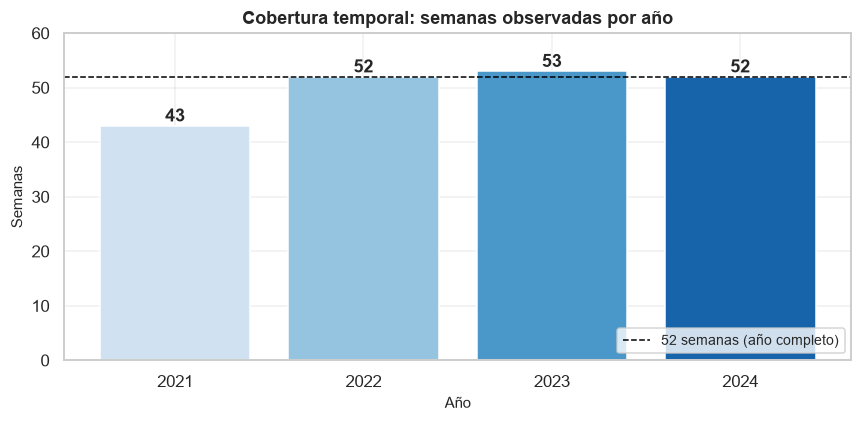

2021 cubre 82.7% de un año (43 de 52 semanas): sus totales anuales no son comparables con 2022–2024 y se reportan solo como referencia.


In [7]:
faltantes = pd.DataFrame({
    "Valores_perdidos": Datos[SERIES].isna().sum(),
    "Porcentaje_perdidos": (100 * Datos[SERIES].isna().mean()).round(2),
    "Ceros": (Datos[SERIES] == 0).sum(),
})
display(faltantes)

cobertura = Datos.groupby("Year").size().rename("Semanas observadas")

fig, ax = plt.subplots(figsize=(8, 4))
barras = ax.bar(cobertura.index.astype(str), cobertura.values,
                color=sns.color_palette("Blues", len(cobertura)))
ax.axhline(52, ls="--", color="black", lw=1, label="52 semanas (año completo)")
for barra, valor in zip(barras, cobertura.values):
    ax.text(barra.get_x() + barra.get_width() / 2, valor + 0.8, str(valor),
            ha="center", fontweight="bold")
ax.set_ylim(0, 60)
ax.set_title("Cobertura temporal: semanas observadas por año")
ax.set_xlabel("Año")
ax.set_ylabel("Semanas")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

print(
    f"2021 cubre {100 * cobertura.loc[2021] / 52:.1f}% de un año "
    f"({cobertura.loc[2021]} de 52 semanas): sus totales anuales no son "
    "comparables con 2022–2024 y se reportan solo como referencia."
)

### 4.2 Estadísticas descriptivas

Además de la media y la desviación estándar, se reportan el **coeficiente de variación (CV)**, la asimetría, la curtosis de exceso y los outliers según el criterio de Tukey (1.5 × IQR). El CV permite comparar la dispersión entre series con escalas muy distintas.

In [8]:
def resumen_descriptivo(df):
    q1 = df.quantile(0.25)
    q3 = df.quantile(0.75)
    iqr = q3 - q1
    outliers = ((df < q1 - 1.5 * iqr) | (df > q3 + 1.5 * iqr)).sum()
    salida = pd.DataFrame({
        "n": df.count(),
        "media": df.mean(),
        "desv_std": df.std(),
        "CV_%": 100 * df.std() / df.mean(),
        "min": df.min(),
        "Q1": q1,
        "mediana": df.median(),
        "Q3": q3,
        "max": df.max(),
        "IQR": iqr,
        "asimetria": df.skew(),
        "curtosis_exceso": df.kurt(),
        "outliers_IQR": outliers,
    })
    return salida.T


descriptivos = resumen_descriptivo(Datos[SERIES])
display(descriptivos.round(2))

inversion_propia = Datos[CANALES].sum(axis=1)

participacion = (
    Datos[CANALES].sum() / Datos[CANALES].sum().sum() * 100
).round(1).rename("Participación en la inversión propia (%)")
display(participacion.to_frame())

print(
    f"La inversión media de competidores ({Datos[COMPETENCIA].mean():.1f}) "
    f"equivale al {100 * Datos[COMPETENCIA].mean() / inversion_propia.mean():.1f}% "
    "de la inversión propia media."
)

,Spend Channel 1,Spend Channel 2,Spend Competitors,Conversions
n,200.00,200.00,200.00,200.00
media,147.04,23.26,30.55,14.02
desv_std,85.85,14.85,21.78,5.22
CV_%,58.39,63.82,71.28,37.21
min,0.70,0.00,0.30,1.60
Q1,74.38,9.98,12.75,10.38
mediana,149.75,22.90,25.75,12.90
Q3,218.82,36.52,45.10,17.40
max,296.40,49.60,114.00,27.00
IQR,144.45,26.55,32.35,7.02


,Participación en la inversión propia (%)
Spend Channel 1,86.3
Spend Channel 2,13.7


La inversión media de competidores (30.6) equivale al 17.9% de la inversión propia media.


**Lectura.** El canal 1 concentra el **86% de la inversión propia** y el canal 2 el 14% restante. La inversión de competidores, que no forma parte del presupuesto propio, equivale a cerca del **18% del gasto propio medio**. El canal 1 es también la serie de mayor escala (media ≈ 147 por semana). Las tres series de gasto presentan una dispersión alta (CV entre 58% y 71%), mientras que las conversiones son más estables (CV ≈ 37%). `Spend Competitors` es la única serie claramente asimétrica a la derecha, con una cola de semanas de alta presión competitiva. El único cero corresponde a una semana sin inversión en el canal 2: es un valor válido, no un dato perdido, y no se imputa.

## 5. Visualización de las series

### 5.1 Nivel, media móvil y volatilidad

Las medias móviles de 4 y 13 semanas separan la señal de la variabilidad semanal. Si existiera una tendencia sostenida, la media de 13 semanas se desplazaría de forma monotónica; si existiera un ciclo anual, se repetiría un patrón cada ~52 semanas.

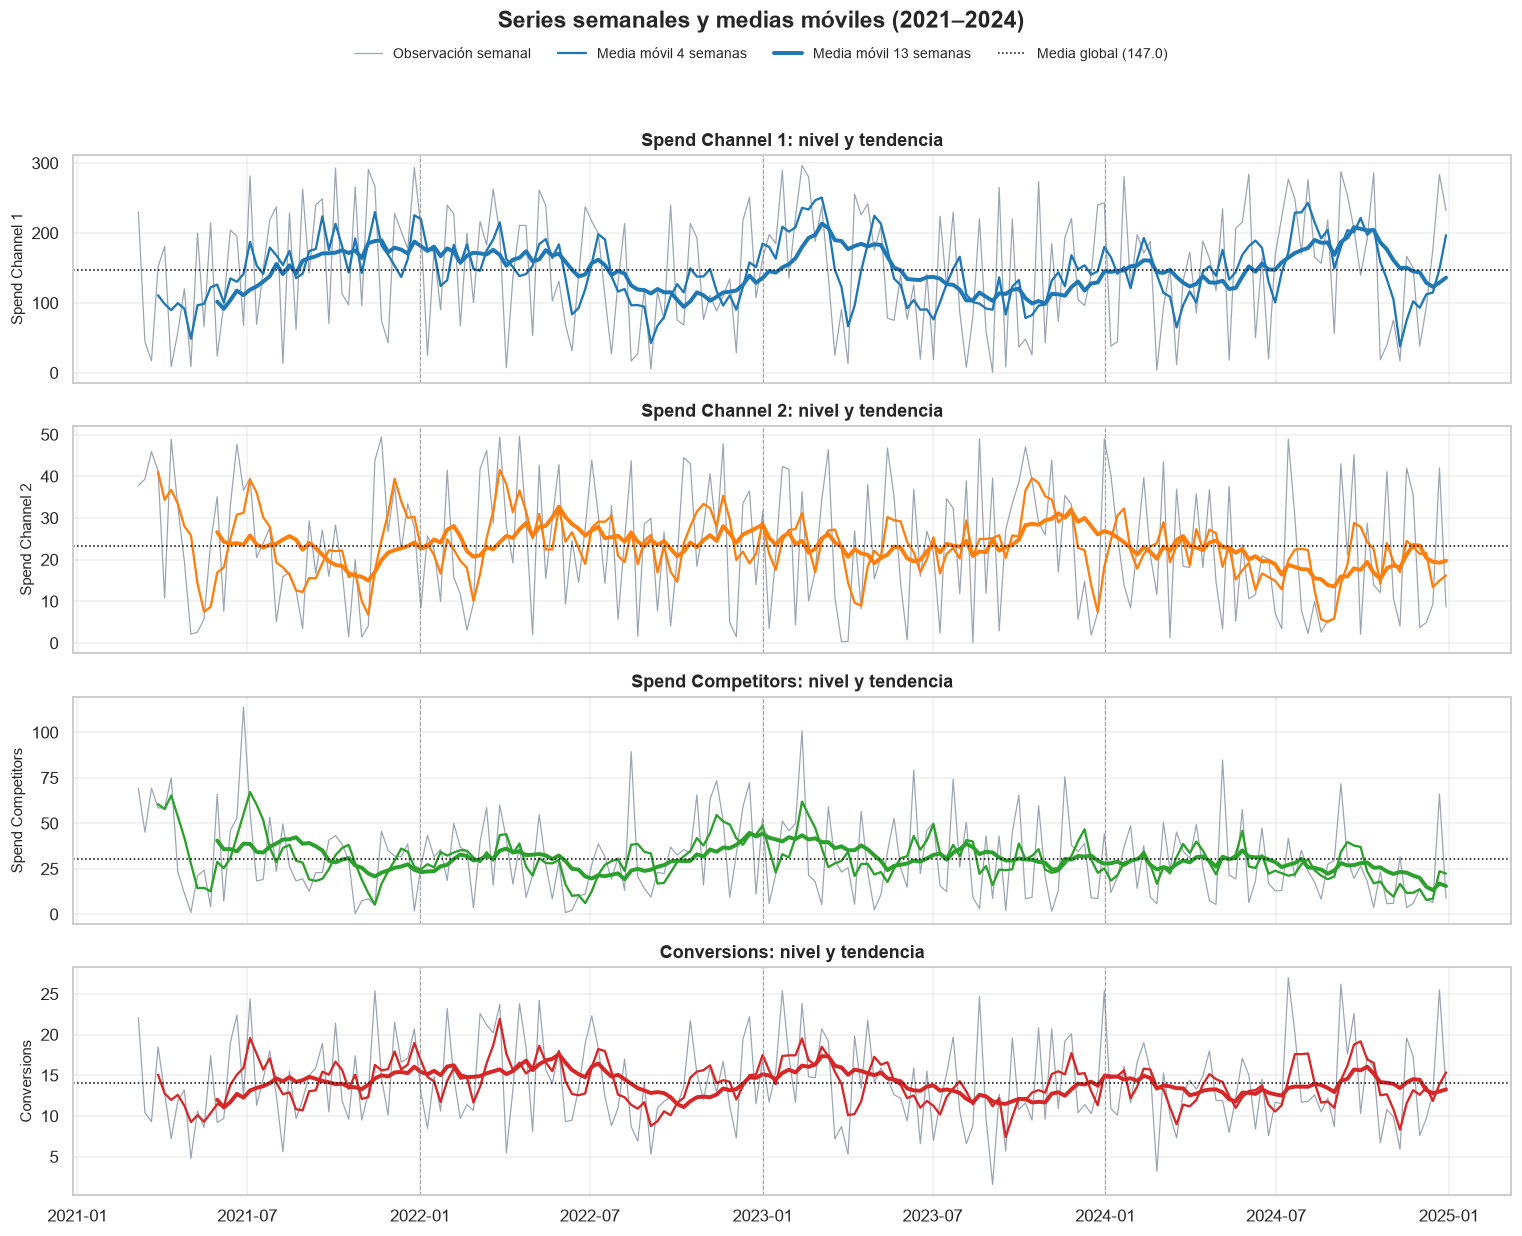

In [9]:
fig, axes = plt.subplots(len(SERIES), 1, figsize=(14, 11), sharex=True)

for ax, col in zip(axes, SERIES):
    serie = Datos[col]
    ax.plot(serie.index, serie, color=COLOR_GRIS, lw=0.8, label="Observación semanal")
    ax.plot(serie.index, serie.rolling(4, min_periods=4).mean(),
            color=COLORES[col], lw=1.5, label="Media móvil 4 semanas")
    ax.plot(serie.index, serie.rolling(13, min_periods=13).mean(),
            color=COLORES[col], lw=2.6, label="Media móvil 13 semanas")
    ax.axhline(serie.mean(), color="black", ls=":", lw=1,
               label=f"Media global ({serie.mean():,.1f})")
    ax.set_ylabel(col)
    ax.set_title(f"{col}: nivel y tendencia")
    for anio in sorted(Datos["Year"].unique())[1:]:
        ax.axvline(pd.Timestamp(f"{anio}-01-01"), color="grey", ls="--", lw=0.7, alpha=0.7)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.suptitle("Series semanales y medias móviles (2021–2024)", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

Ninguna media móvil de 13 semanas muestra una deriva sostenida: oscilan alrededor de una media estable. Tampoco se observa un patrón que se repita cada año. La impresión visual es la de **ruido alrededor de un nivel constante**, con picos puntuales que se investigan en la sección 9.

### 5.2 Comparación por año (semana ISO)

Superponer los años en el eje de semana ISO permite evaluar si el patrón intraanual se repite. Si hubiera estacionalidad, las cuatro curvas tenderían a subir y bajar en las mismas semanas.

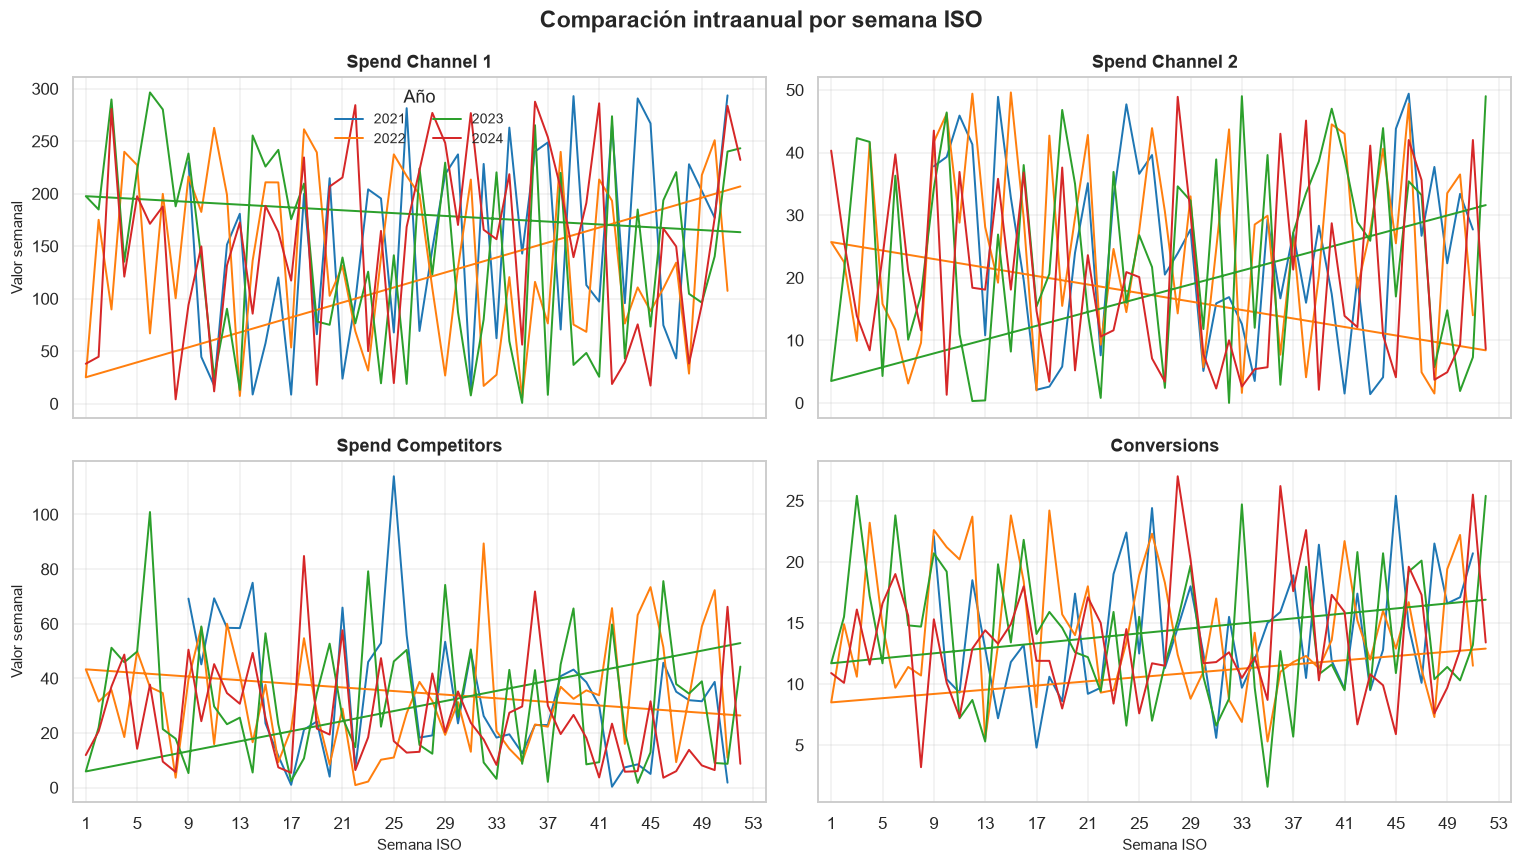

In [10]:
anios = sorted(Datos["Year"].unique())
paleta_anios = dict(zip(anios, sns.color_palette("tab10", n_colors=len(anios))))

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
for ax, col in zip(axes.ravel(), SERIES):
    for anio, grupo in Datos.groupby("Year"):
        ax.plot(grupo["WeekNumber"], grupo[col], color=paleta_anios[anio],
                lw=1.3, label=str(anio))
    ax.set_title(col)
    ax.set_xticks(range(1, 54, 4))
    ax.set_xlim(0, 54)

axes[0, 0].legend(title="Año", ncol=2, frameon=False)
for ax in axes[1]:
    ax.set_xlabel("Semana ISO")
for ax in axes[:, 0]:
    ax.set_ylabel("Valor semanal")
fig.suptitle("Comparación intraanual por semana ISO", fontsize=15, fontweight="bold", y=0.98)
plt.tight_layout()
plt.show()

Las curvas se cruzan y no mantienen un orden estable: no hay un patrón anual recurrente. La única diferencia sistemática es de nivel entre series, no de forma estacional.

### 5.3 Vista mensual y eficiencia

La agregación mensual suaviza el ruido semanal y expresa las series en la unidad de decisión habitual (mes). En el tercer panel se resume la **eficiencia global**: conversiones por cada 100 unidades de inversión propia (canales 1 y 2). Es un indicador agregado, no incremental; su lectura correcta se retoma en la sección 10.

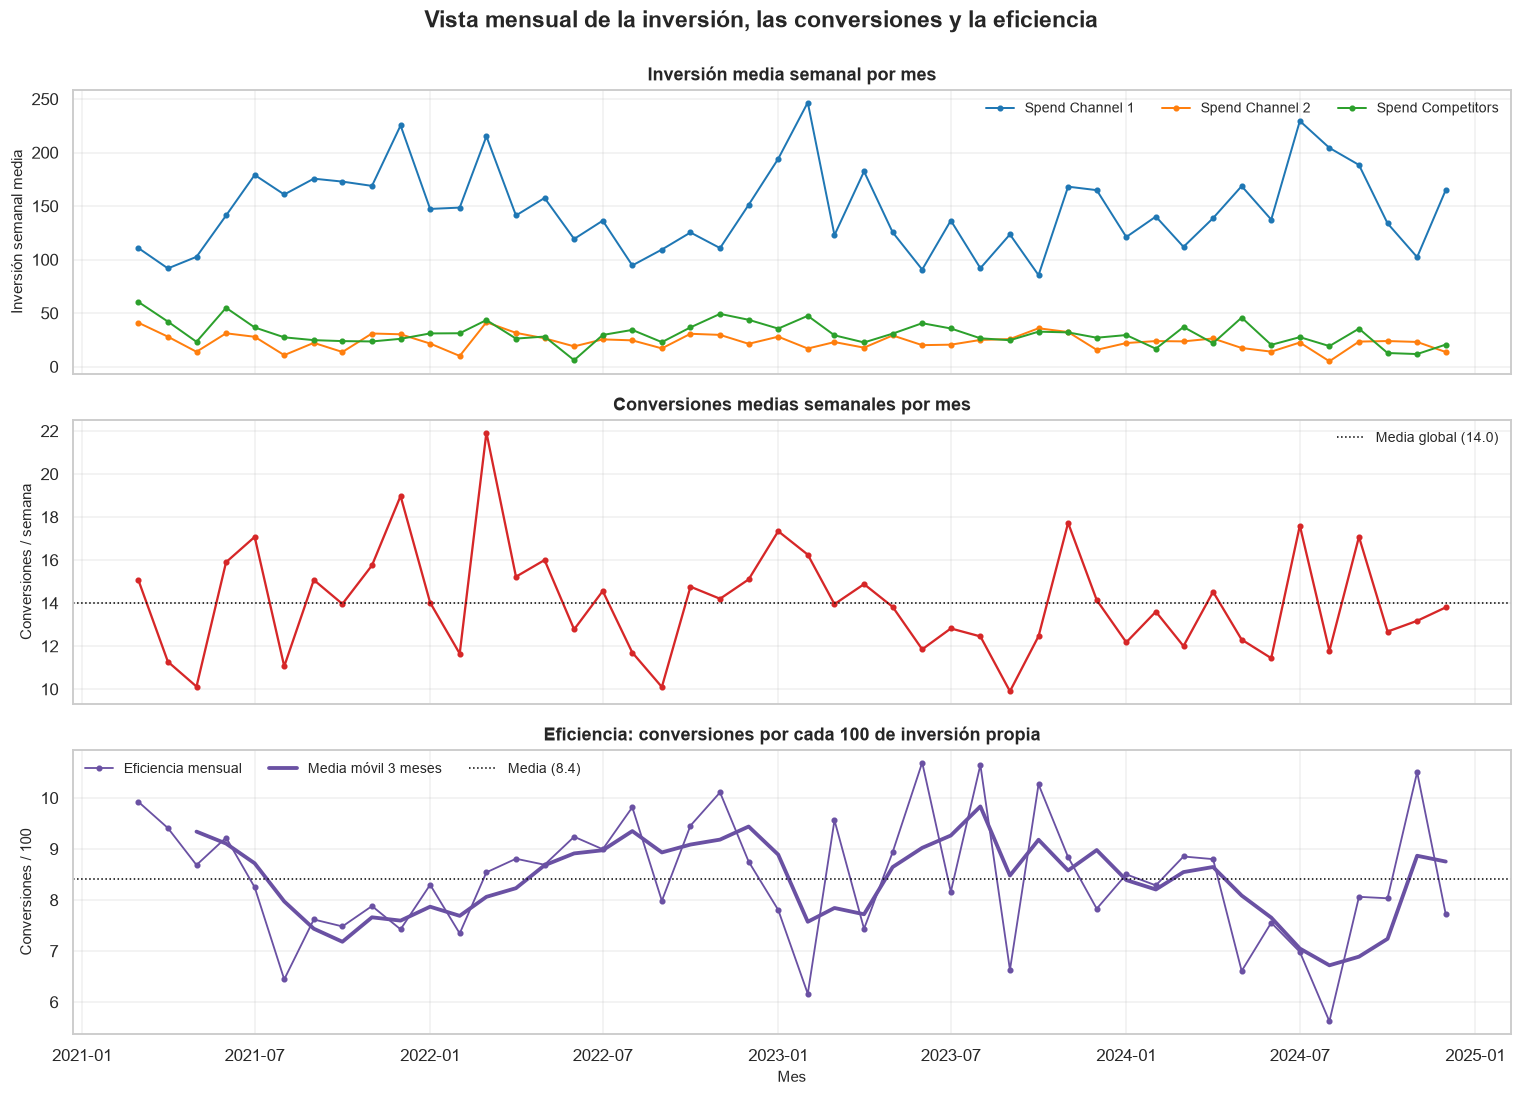

Eficiencia global media: 8.41 conversiones por cada 100 de inversión (rango mensual 5.62–10.69).


In [11]:
mensual = Datos[SERIES].resample("MS").mean()

conv_mes = Datos[OBJETIVO].resample("MS").sum()
gasto_mes = inversion_propia.resample("MS").sum()
eficiencia_mes = (conv_mes / gasto_mes * 100).rename("Conversiones por 100 de inversión")

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

for col in GASTOS:
    axes[0].plot(mensual.index, mensual[col], marker="o", ms=3,
                 color=COLORES[col], lw=1.3, label=col)
axes[0].set_title("Inversión media semanal por mes")
axes[0].set_ylabel("Inversión semanal media")
axes[0].legend(ncol=3, frameon=False)

axes[1].plot(mensual.index, mensual[OBJETIVO], marker="o", ms=3,
             color=COLORES[OBJETIVO], lw=1.5)
axes[1].axhline(Datos[OBJETIVO].mean(), color="black", ls=":", lw=1,
                label=f"Media global ({Datos[OBJETIVO].mean():.1f})")
axes[1].set_title("Conversiones medias semanales por mes")
axes[1].set_ylabel("Conversiones / semana")
axes[1].legend(frameon=False)

axes[2].plot(eficiencia_mes.index, eficiencia_mes, color="#6a51a3",
             marker="o", ms=3, lw=1.2, label="Eficiencia mensual")
axes[2].plot(eficiencia_mes.index, eficiencia_mes.rolling(3).mean(),
             color="#6a51a3", lw=2.5, label="Media móvil 3 meses")
axes[2].axhline(eficiencia_mes.mean(), color="black", ls=":", lw=1,
                label=f"Media ({eficiencia_mes.mean():.1f})")
axes[2].set_title("Eficiencia: conversiones por cada 100 de inversión propia")
axes[2].set_ylabel("Conversiones / 100")
axes[2].set_xlabel("Mes")
axes[2].legend(ncol=3, frameon=False)

fig.suptitle("Vista mensual de la inversión, las conversiones y la eficiencia",
             fontsize=15, fontweight="bold", y=0.995)
plt.tight_layout()
plt.show()

print(
    f"Eficiencia global media: {eficiencia_mes.mean():.2f} conversiones por cada "
    f"100 de inversión (rango mensual {eficiencia_mes.min():.2f}–{eficiencia_mes.max():.2f})."
)

El nivel de inversión y de conversiones se mantiene dentro de una banda estrecha; la eficiencia mensual fluctúa sin una tendencia clara. Los meses de los extremos (marzo de 2021 y diciembre de 2024) están incompletos y se interpretan con cautela.

## 6. Tendencia

### 6.1 Prueba formal de tendencia lineal

Para cada serie se estima `y(t) = α + β·t + ε(t)`, donde `t` es el número de semana. Se reporta la pendiente **anualizada** (β × 52) y su intervalo de confianza al 95% calculado con errores estándar **HAC** (Newey-West, 4 rezagos), que son válidos incluso si existe autocorrelación o heterocedasticidad. El p-valor HAC es la referencia conservadora.

In [12]:
t = np.arange(len(Datos))
filas = []
for col in SERIES:
    y = Datos[col].to_numpy(dtype=float)
    modelo_ols = sm.OLS(y, sm.add_constant(t)).fit()
    modelo_hac = sm.OLS(y, sm.add_constant(t)).fit(
        cov_type="HAC", cov_kwds={"maxlags": 4}
    )
    b = modelo_hac.params[1]
    se = modelo_hac.bse[1]
    filas.append({
        "Serie": col,
        "Pendiente semanal": b,
        "Pendiente anual (×52)": b * 52,
        "IC 95% inf (anual)": (b - 1.96 * se) * 52,
        "IC 95% sup (anual)": (b + 1.96 * se) * 52,
        "p-valor OLS": modelo_ols.pvalues[1],
        "p-valor HAC": modelo_hac.pvalues[1],
        "R²": modelo_hac.rsquared,
        "Cambio anual vs media (%)": 100 * b * 52 / Datos[col].mean(),
    })

tendencia = pd.DataFrame(filas).set_index("Serie")
tendencia["Significativa al 5%"] = np.where(tendencia["p-valor HAC"] < 0.05, "Sí", "No")
display(tendencia.round(3))

,Pendiente semanal,Pendiente anual (×52),IC 95% inf (anual),IC 95% sup (anual),p-valor OLS,p-valor HAC,R²,Cambio anual vs media (%),Significativa al 5%
Serie,,,,,,,,,
Spend Channel 1,0.026,1.366,-9.985,12.718,0.803,0.813,0.000,0.929,No
Spend Channel 2,-0.028,-1.476,-3.460,0.507,0.119,0.145,0.012,-6.346,No
Spend Competitors,-0.058,-3.032,-6.178,0.114,0.028,0.059,0.024,-9.922,No
Conversions,-0.005,-0.242,-0.888,0.404,0.468,0.463,0.003,-1.725,No


Ninguna serie presenta una tendencia lineal significativa al 5% con inferencia HAC. El caso más cercano es `Spend Competitors` (caída de ≈ 3.0 unidades por año, p ≈ 0.06): una señal **marginal**, no concluyente, coherente con la caída observada en 2024 pero insuficiente para hablar de una tendencia estructural. Las conversiones no muestran deriva (β anual ≈ −0.24, p ≈ 0.46).

### 6.2 Agregación anual y CPA global

Los totales anuales resumen el negocio, pero deben interpretarse con dos precauciones: 2021 está incompleto y el CPA agregado usa toda la inversión propia, no las conversiones incrementales del modelo.

In [13]:
anual = pd.DataFrame({
    "Semanas": Datos.groupby("Year").size(),
    "Inversión propia total": inversion_propia.groupby(Datos["Year"]).sum(),
    "Inversión propia media semanal": inversion_propia.groupby(Datos["Year"]).mean(),
    "Gasto en competidores total": Datos[COMPETENCIA].groupby(Datos["Year"]).sum(),
    "Conversiones totales": Datos[OBJETIVO].groupby(Datos["Year"]).sum(),
    "Conversiones medias semanales": Datos[OBJETIVO].groupby(Datos["Year"]).mean(),
})
anual["CPA global (inversión / conversiones)"] = (
    anual["Inversión propia total"] / anual["Conversiones totales"]
)
anual["Var. conv. medias vs año previo (%)"] = (
    anual["Conversiones medias semanales"].pct_change() * 100
)
anual["Año completo"] = np.where(anual["Semanas"] >= 52, "Sí", "No")

display(anual.round(2))

,Semanas,Inversión propia total,Inversión propia media semanal,Gasto en competidores total,Conversiones totales,Conversiones medias semanales,CPA global (inversión / conversiones),Var. conv. medias vs año previo (%),Año completo
Year,,,,,,,,,
2021,43,7591.2,176.54,1447.8,612.2,14.24,12.40,NaN,No
2022,52,8495.4,163.37,1657.9,747.4,14.37,11.37,0.95,Sí
2023,53,8974.3,169.33,1694.8,742.0,14.00,12.09,-2.60,Sí
2024,52,9000.4,173.08,1310.3,702.9,13.52,12.80,-3.45,Sí


**Lectura de negocio.** Para evitar el sesgo del año incompleto, la comparación se hace entre 2022 y 2024. La inversión propia total pasó de 8.5 mil a 9.0 mil, un **+5.9% en términos de inversión media semanal** (163.4 → 173.1). Las conversiones semanales, en cambio, **cayeron −5.9%** (14.37 → 13.52). En consecuencia, el **CPA global subió de 11.4 a 12.8** (+12.6%). La caída de 2024 coincide con recortes en el canal 2 (−17.8% en media semanal) y en la presión de competidores (−21.2%), mientras el canal 1 aumentó (+5.5%). Esta asociación es descriptiva; la atribución causal corresponde al modelo.

## 7. Estacionalidad

### 7.1 Descomposición clásica (exploratoria)

La descomposición aditiva separa cada serie en tendencia (media móvil centrada de 52 semanas), componente estacional (patrón fijo por semana del año) y residuo: `y(t) = Tendencia(t) + Estacional(t) + Residuo(t)`.

> **Advertencia metodológica.** Con 200 semanas hay menos de cuatro ciclos anuales completos. La tendencia en los extremos se extrapola y el componente estacional se estima con solo ~4 observaciones por semana del año, por lo que es **ruidoso** y no debe interpretarse por sí solo como evidencia de estacionalidad. Las pruebas formales de la sección 7.2 son las que deciden; aquí la descomposición sirve para obtener una **tendencia suave** y un **residuo** para inspección.

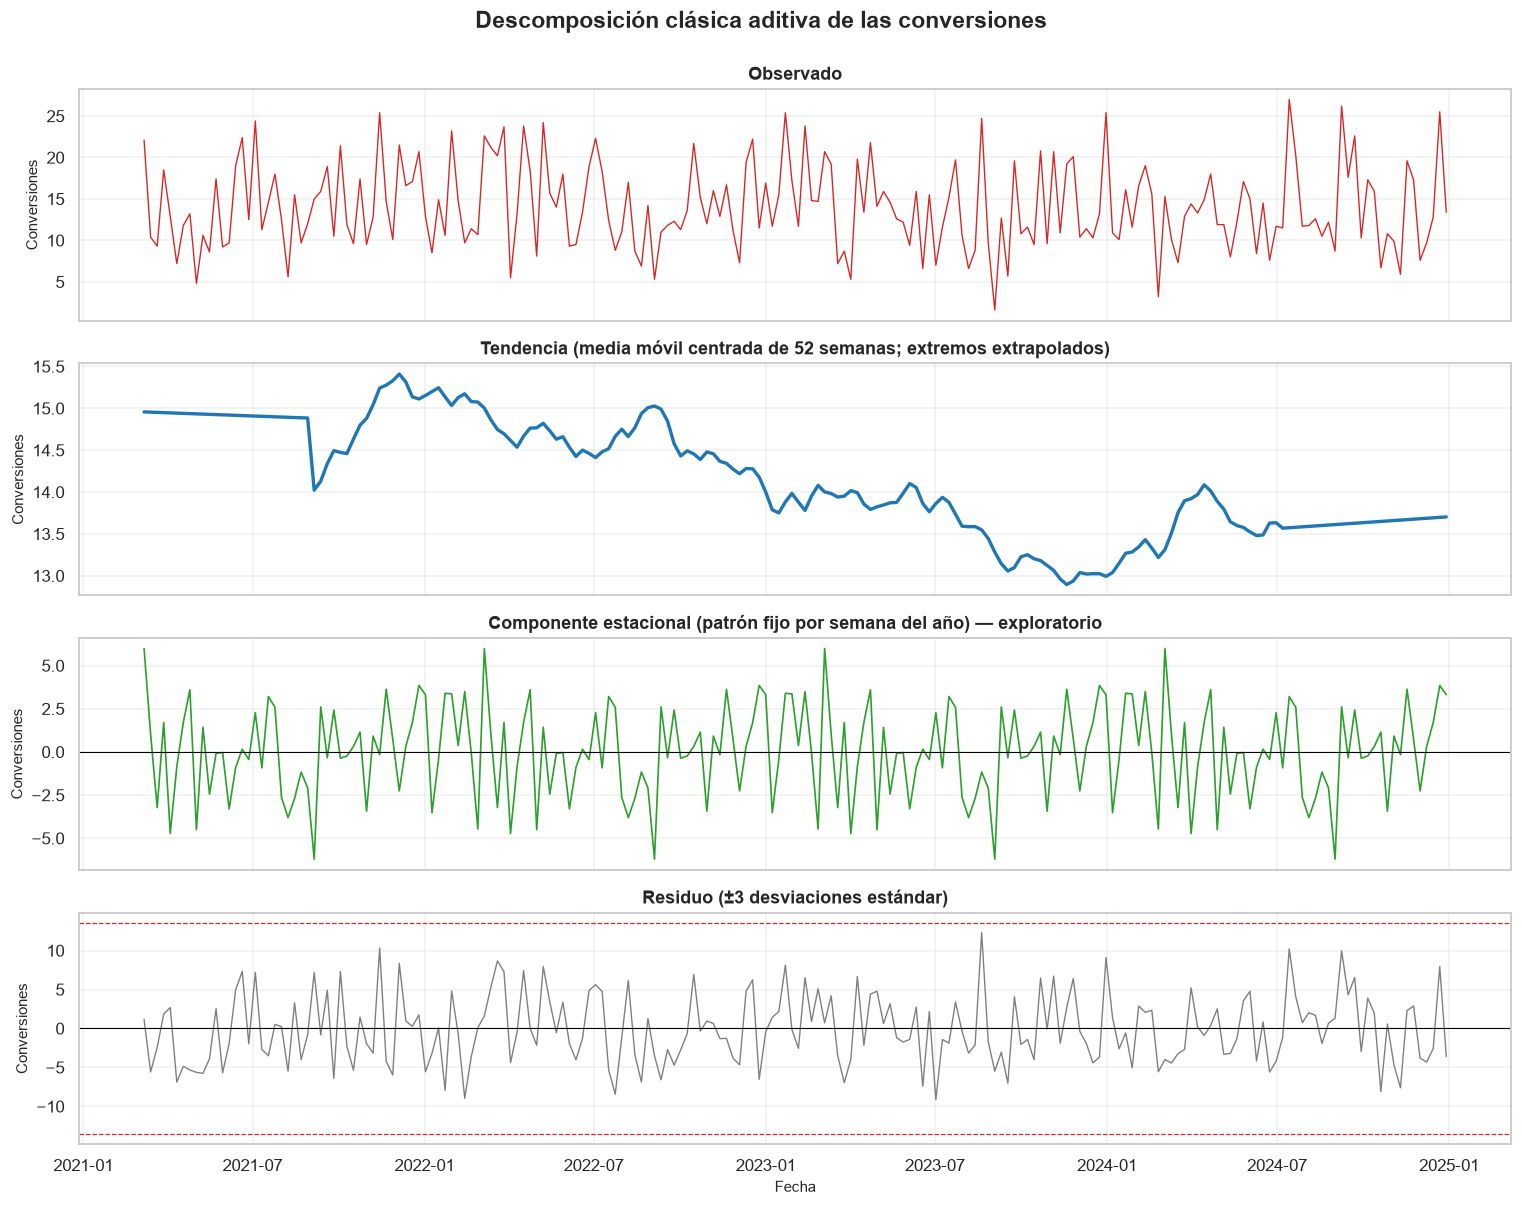

In [14]:
descomposicion = {
    col: seasonal_decompose(
        Datos[col], model="additive", period=PERIODO_ANUAL,
        extrapolate_trend="period",
    )
    for col in SERIES
}

res = descomposicion[OBJETIVO]
fig, axes = plt.subplots(4, 1, figsize=(14, 11), sharex=True)

axes[0].plot(res.observed, color=COLORES[OBJETIVO], lw=0.9)
axes[0].set_title("Observado")

axes[1].plot(res.trend, color="#1f77b4", lw=2.2)
axes[1].set_title("Tendencia (media móvil centrada de 52 semanas; extremos extrapolados)")

axes[2].plot(res.seasonal, color="#2ca02c", lw=1.1)
axes[2].axhline(0, color="black", lw=0.7)
axes[2].set_title("Componente estacional (patrón fijo por semana del año) — exploratorio")

axes[3].plot(res.resid, color="#7f7f7f", lw=0.9)
axes[3].axhline(0, color="black", lw=0.7)
desv_resid = res.resid.std()
axes[3].axhline(3 * desv_resid, color="#d62728", ls="--", lw=0.8)
axes[3].axhline(-3 * desv_resid, color="#d62728", ls="--", lw=0.8)
axes[3].set_title("Residuo (±3 desviaciones estándar)")

for ax in axes:
    ax.set_ylabel("Conversiones")
axes[-1].set_xlabel("Fecha")
fig.suptitle("Descomposición clásica aditiva de las conversiones", fontsize=15, fontweight="bold", y=0.995)
plt.tight_layout()
plt.show()

La tendencia se mueve en una banda estrecha (≈ 13–15.4 conversiones por semana) y el residuo concentra la mayor parte de la varianza. El componente estacional tiene una amplitud visible (≈ ±6 conversiones), pero esa estimación promedia apenas cuatro valores por semana del año; la sección 7.2 comprueba si es distinguible del ruido. Los tramos rectos al inicio y al final de la tendencia son extrapolaciones y no deben interpretarse como dinámica observada.

### 7.2 Pruebas formales de estacionalidad

Se triangula con tres enfoques:

1. **Regresión con dummies mensuales:** porcentaje de varianza explicado por el mes (R²) y prueba F conjunta.
2. **Kruskal-Wallis:** diferencia de niveles entre meses sin supuesto de normalidad.
3. **Autocorrelación en el rezago 52:** si hay ciclo anual, la correlación con la misma semana del año anterior debe ser positiva y significativa.

Si la estacionalidad fuera relevante, los tres deberían coincidir en señalizar el patrón.

In [15]:
def r2_meses(serie):
    dummies = pd.get_dummies(serie.index.month, prefix="Mes", drop_first=True).astype(float)
    dummies.index = serie.index
    modelo = sm.OLS(serie, sm.add_constant(dummies)).fit()
    return modelo.rsquared, modelo.f_pvalue


filas = []
for col in SERIES:
    serie = Datos[col]
    r2, p_f = r2_meses(serie)
    grupos = [g[col].values for _, g in Datos.groupby("Month")]
    p_kw = stats.kruskal(*grupos).pvalue
    r52 = serie.autocorr(lag=PERIODO_ANUAL)
    banda = 1.96 / np.sqrt(len(serie))
    filas.append({
        "Serie": col,
        "R² dummies mensuales": r2,
        "p-valor F (meses)": p_f,
        "p-valor Kruskal-Wallis": p_kw,
        "ACF(52)": r52,
        "¿ACF(52) fuera de banda?": "Sí" if abs(r52) > banda else "No",
    })

estacionalidad = pd.DataFrame(filas).set_index("Serie")
estacionalidad["¿Estacionalidad al 5%?"] = np.where(
    (estacionalidad["p-valor F (meses)"] < 0.05)
    | (estacionalidad["p-valor Kruskal-Wallis"] < 0.05)
    | (estacionalidad["¿ACF(52) fuera de banda?"] == "Sí"),
    "Sí", "No",
)
display(estacionalidad.round(3))
print(f"Banda de confianza al 95% para ACF(52): ±{banda:.3f}")

,R² dummies mensuales,p-valor F (meses),p-valor Kruskal-Wallis,ACF(52),¿ACF(52) fuera de banda?,¿Estacionalidad al 5%?
Serie,,,,,,
Spend Channel 1,0.039,0.752,0.727,0.006,No,No
Spend Channel 2,0.087,0.094,0.114,0.096,No,No
Spend Competitors,0.035,0.815,0.515,-0.059,No,No
Conversions,0.050,0.539,0.612,0.075,No,No


Banda de confianza al 95% para ACF(52): ±0.139


### 7.3 Perfil mensual

Los boxplots muestran la distribución de cada serie por mes, agregando los cuatro años. Si existiera un mes sistemáticamente distinto, la caja se desplazaría de forma clara respecto de las demás.

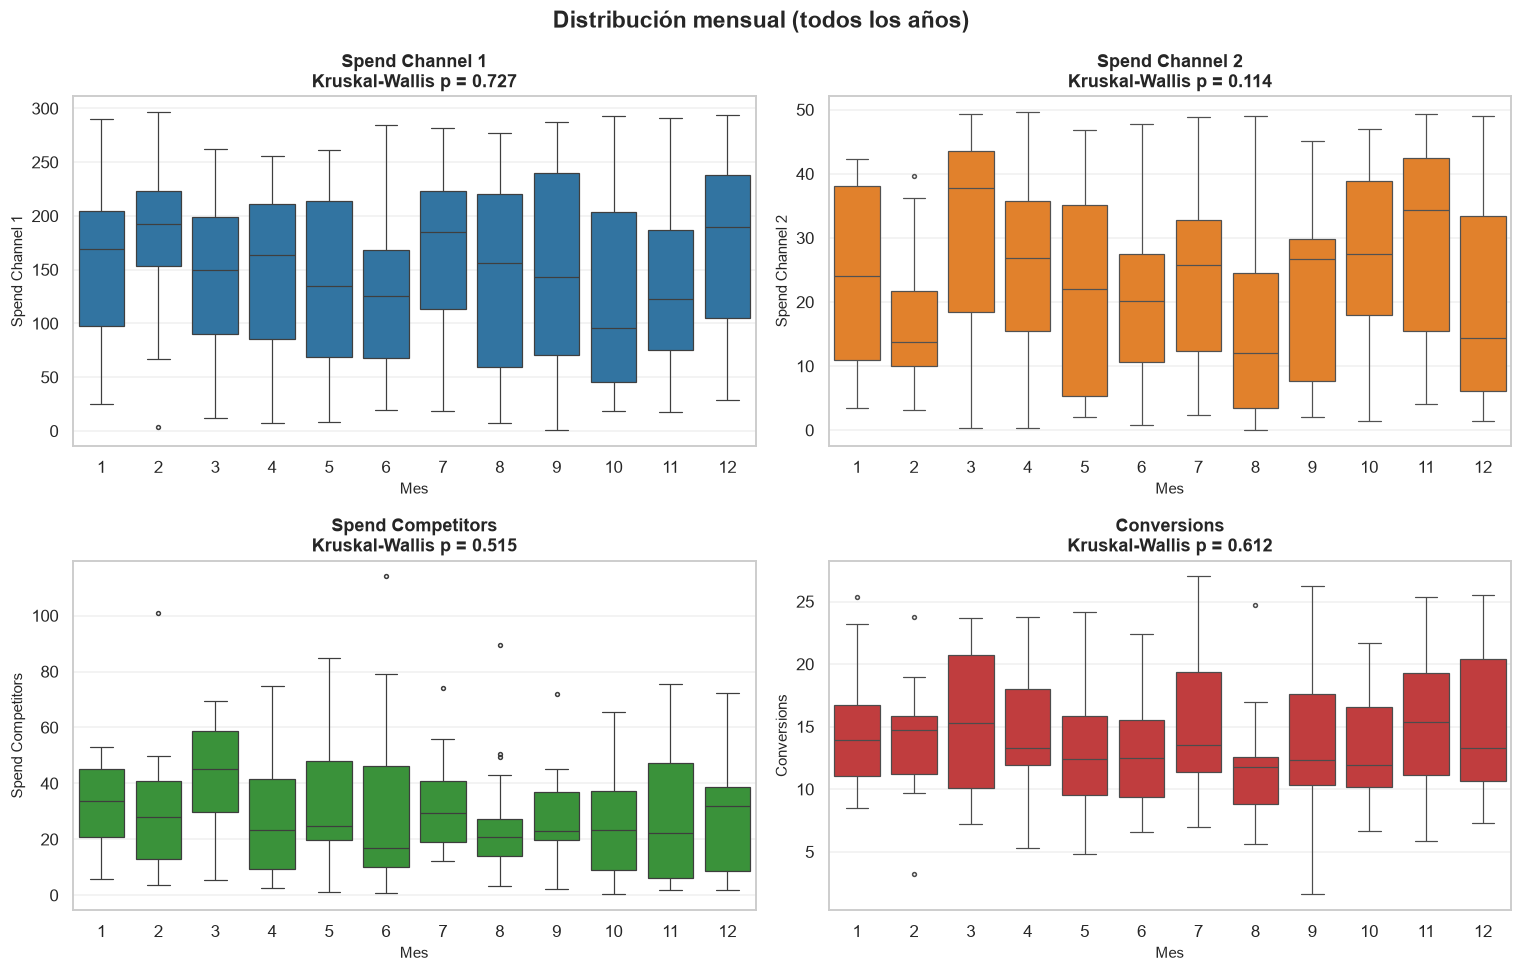

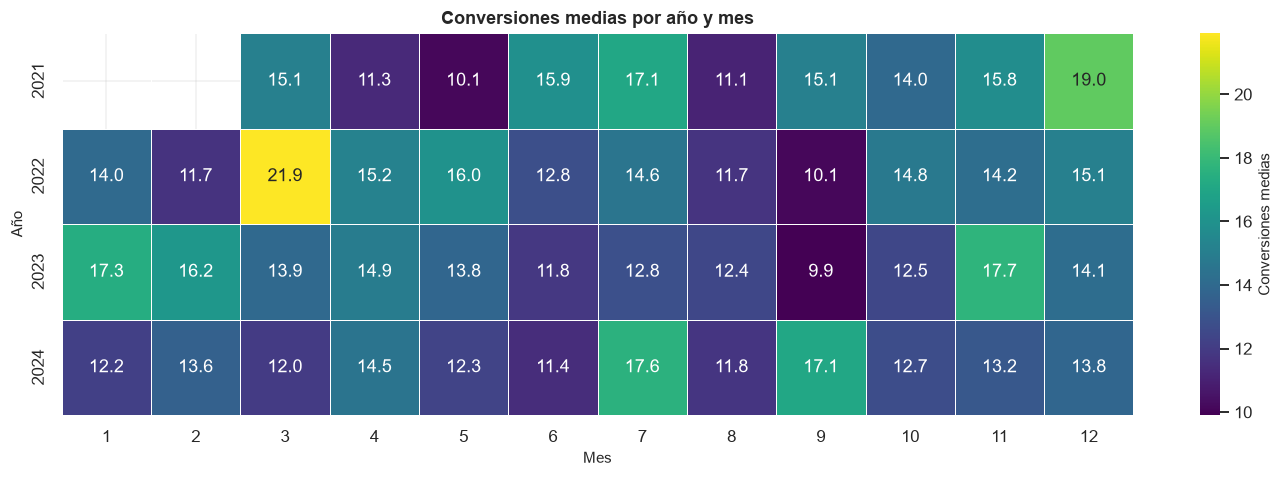

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.ravel(), SERIES):
    sns.boxplot(data=Datos, x="Month", y=col, color=COLORES[col],
                fliersize=2.5, linewidth=0.8, ax=ax)
    p_kw = stats.kruskal(*[g[col].values for _, g in Datos.groupby("Month")]).pvalue
    ax.set_title(f"{col}\nKruskal-Wallis p = {p_kw:.3f}")
    ax.set_xlabel("Mes")
    ax.set_ylabel(col)
fig.suptitle("Distribución mensual (todos los años)", fontsize=15, fontweight="bold", y=0.98)
plt.tight_layout()
plt.show()

pivote = Datos.pivot_table(index="Year", columns="Month", values=OBJETIVO, aggfunc="mean")
fig, ax = plt.subplots(figsize=(13, 4.5))
sns.heatmap(pivote, annot=True, fmt=".1f", cmap="viridis", mask=pivote.isna(),
            linewidths=0.5, cbar_kws={"label": "Conversiones medias"}, ax=ax)
ax.set_title("Conversiones medias por año y mes")
ax.set_xlabel("Mes")
ax.set_ylabel("Año")
plt.tight_layout()
plt.show()

**Conclusión de estacionalidad.** Ninguna de las tres pruebas detecta un patrón anual: los R² mensuales son bajos (≈ 4–9%), las pruebas F y Kruskal-Wallis no rechazan la igualdad entre meses y la autocorrelación en el rezago 52 está dentro de la banda de confianza. El único p-valor marginal es el del canal 2 en la prueba F (≈ 0.09), que no se replica en Kruskal-Wallis ni en ACF(52). Por tanto, **no se incorpora estacionalidad al modelo**; si en el futuro se dispone de más años, conviene reevaluarla.

## 8. Estacionariedad y autocorrelación

### 8.1 Pruebas de raíz unitaria

Se combinan ADF (hipótesis nula: raíz unitaria) y KPSS (hipótesis nula: estacionariedad). La lectura conjunta es más robusta que cualquiera de las dos por separado:

| ADF | KPSS | Interpretación |
|---|---|---|
| Rechaza raíz unitaria (p < 0.05) | No rechaza estacionariedad (p > 0.05) | Estacionaria |
| No rechaza raíz unitaria | Rechaza estacionariedad | No estacionaria |
| Conclusiones opuestas | | Evidencia mixta |

In [17]:
filas = []
for col in SERIES:
    serie = Datos[col].dropna()
    adf_stat, adf_p = adfuller(serie, regression="c", autolag="AIC")[:2]
    kpss_stat, kpss_p = kpss(serie, regression="c", nlags="auto")[:2]

    if adf_p < 0.05 and kpss_p > 0.05:
        conclusion = "Estacionaria"
    elif adf_p >= 0.05 and kpss_p <= 0.05:
        conclusion = "No estacionaria (raíz unitaria)"
    else:
        conclusion = "Evidencia mixta"

    filas.append({
        "Serie": col,
        "ADF estadístico": adf_stat,
        "ADF p-valor": adf_p,
        "KPSS estadístico": kpss_stat,
        "KPSS p-valor": kpss_p,
        "Conclusión": conclusion,
    })

estacionariedad = pd.DataFrame(filas).set_index("Serie")
display(estacionariedad.round(4))

,ADF estadístico,ADF p-valor,KPSS estadístico,KPSS p-valor,Conclusión
Serie,,,,,
Spend Channel 1,-14.1581,0.0,0.0862,0.1000,Estacionaria
Spend Channel 2,-14.1299,0.0,0.2825,0.1000,Estacionaria
Spend Competitors,-13.3442,0.0,0.4012,0.0766,Estacionaria
Conversions,-13.9902,0.0,0.1373,0.1000,Estacionaria


Las cuatro series son **estacionarias en nivel**: ADF rechaza la raíz unitaria (p < 0.001) y KPSS no rechaza la estacionariedad (p ≥ 0.077). No es necesario diferenciar para modelar; hacerlo introduciría una serie sobre-diferenciada.

### 8.2 ACF y PACF

Los correlogramas muestran la dependencia lineal con los rezagos 1 a 40. En una serie con tendencia, la ACF decae lentamente; con estacionalidad, aparecen picos en 52, 104, etc.; con un proceso autorregresivo, la ACF decae y la PACF se corta.

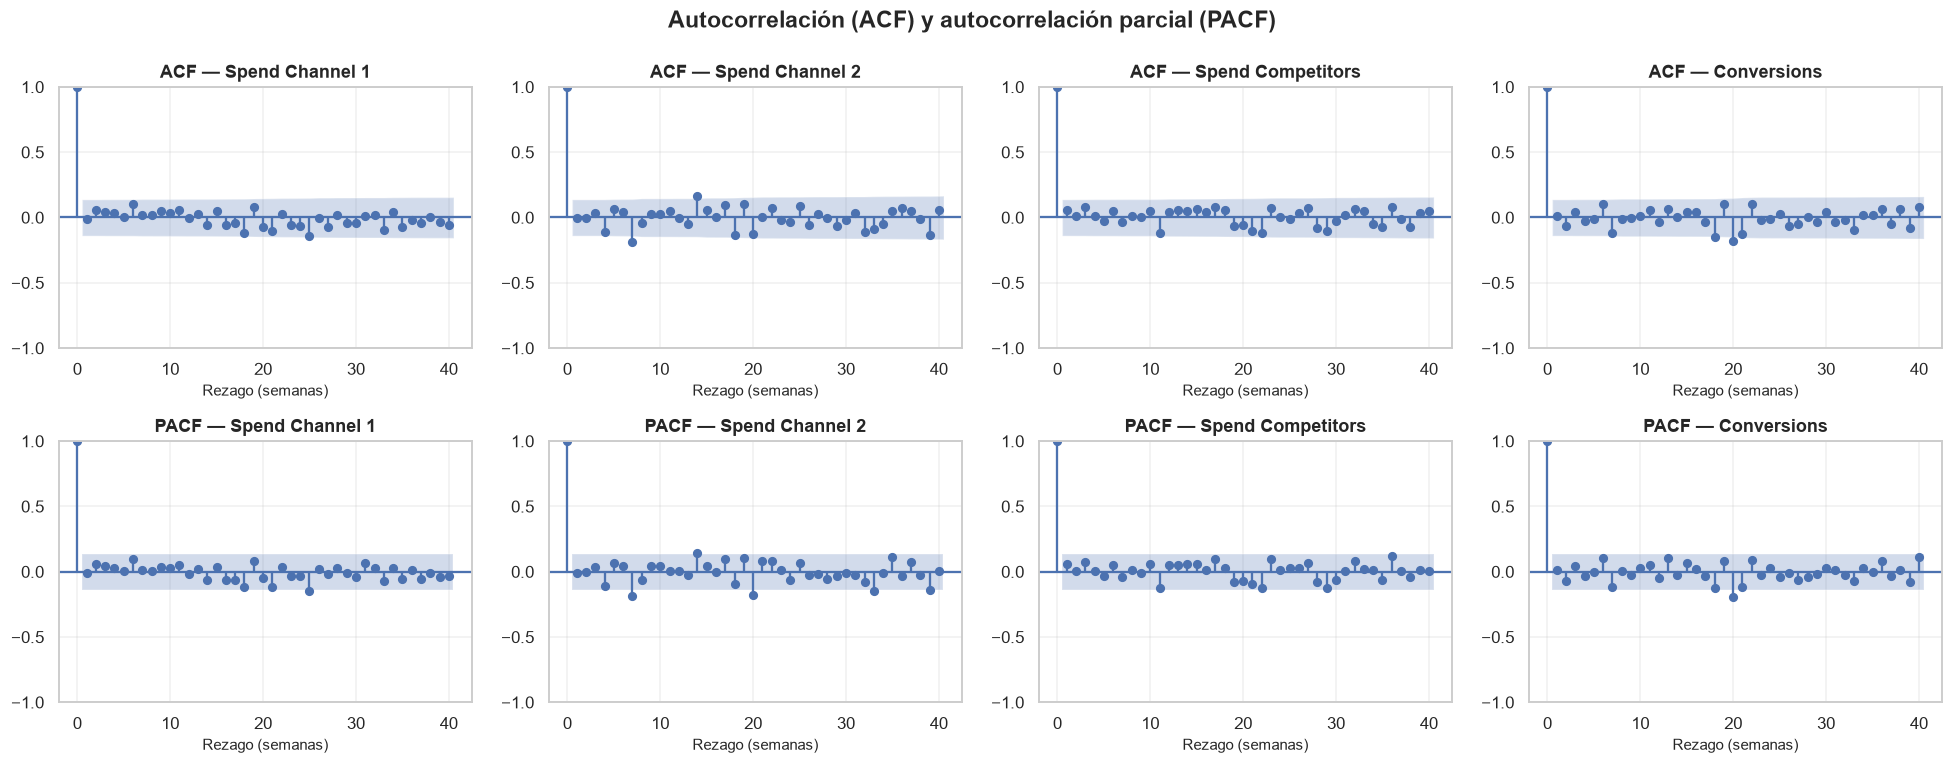

In [18]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for j, col in enumerate(SERIES):
    plot_acf(Datos[col], lags=40, alpha=0.05, ax=axes[0, j],
             title=f"ACF — {col}")
    plot_pacf(Datos[col], lags=40, alpha=0.05, method="ywm", ax=axes[1, j],
              title=f"PACF — {col}")
    axes[0, j].set_xlabel("Rezago (semanas)")
    axes[1, j].set_xlabel("Rezago (semanas)")
fig.suptitle("Autocorrelación (ACF) y autocorrelación parcial (PACF)",
             fontsize=15, fontweight="bold", y=0.99)
plt.tight_layout()
plt.show()

### 8.3 Prueba de Ljung-Box

La prueba de Ljung-Box evalúa de forma conjunta si los primeros `m` coeficientes de autocorrelación son cero. Se aplica a varios horizontes, incluido el anual (52 semanas).

In [19]:
rezagos = [4, 8, 13, 26, 52]
lb_p = pd.DataFrame({
    col: acorr_ljungbox(Datos[col], lags=rezagos, return_df=True)["lb_pvalue"]
    for col in SERIES
})
lb_p.index.name = "Rezagos (semanas)"
display(lb_p.round(4))

lb_estad = pd.DataFrame({
    col: acorr_ljungbox(Datos[col], lags=rezagos, return_df=True)["lb_stat"]
    for col in SERIES
})
display(lb_estad.round(2))

,Spend Channel 1,Spend Channel 2,Spend Competitors,Conversions
Rezagos (semanas),,,,
4,0.8517,0.6143,0.7517,0.8336
8,0.8840,0.1580,0.9395,0.5631
13,0.9673,0.4245,0.8796,0.7961
26,0.6762,0.0898,0.7604,0.2057
52,0.9233,0.2417,0.8907,0.4085


,Spend Channel 1,Spend Channel 2,Spend Competitors,Conversions
4,1.36,2.67,1.91,1.46
8,3.69,11.85,2.92,6.76
13,5.33,13.31,7.41,8.69
26,22.23,36.10,20.64,31.63
52,38.21,58.76,39.87,53.71


**Conclusión de dependencia temporal.** No se rechaza la ausencia de autocorrelación en ninguno de los horizontes: el p-valor mínimo es ≈ 0.09 (canal 2 a 26 semanas), y a 4, 8, 13 y 52 semanas todos superan 0.15. Las series se comportan como ruido alrededor de su media: **el pasado inmediato no aporta información predictiva lineal** sobre la semana siguiente. Esto no implica independencia en sentido estricto (puede haber dependencia no lineal), pero descarta la necesidad de términos AR, MA o diferenciación.

### 8.4 Implicancia práctica

Si las series no tienen memoria, un modelo con rezagos de la propia variable (ARIMA, AR) no aportará valor y solo añadirá parámetros. La información relevante, si existe, debe estar en la **relación contemporánea con las variables de inversión**. Eso es lo que se examina a continuación.

## 9. Relación dinámica entre inversión y conversiones

### 9.1 Correlación cruzada (CCF)

La CCF mide la correlación entre la inversión en la semana `t` y las conversiones en `t+k`. Un pico en `k > 0` indicaría **carry-over** (la inversión tarda en convertir); un pico en `k < 0`, anticipación.

La banda punteada es el 95% de confianza individual (±1.96/√n). Como se examinan 25 rezagos, también se dibuja la banda corregida por comparaciones múltiples (Bonferroni), más exigente. Las barras se colorean en rojo **solo si superan la banda de Bonferroni**; fuera del rezago 0, ninguna lo consigue.

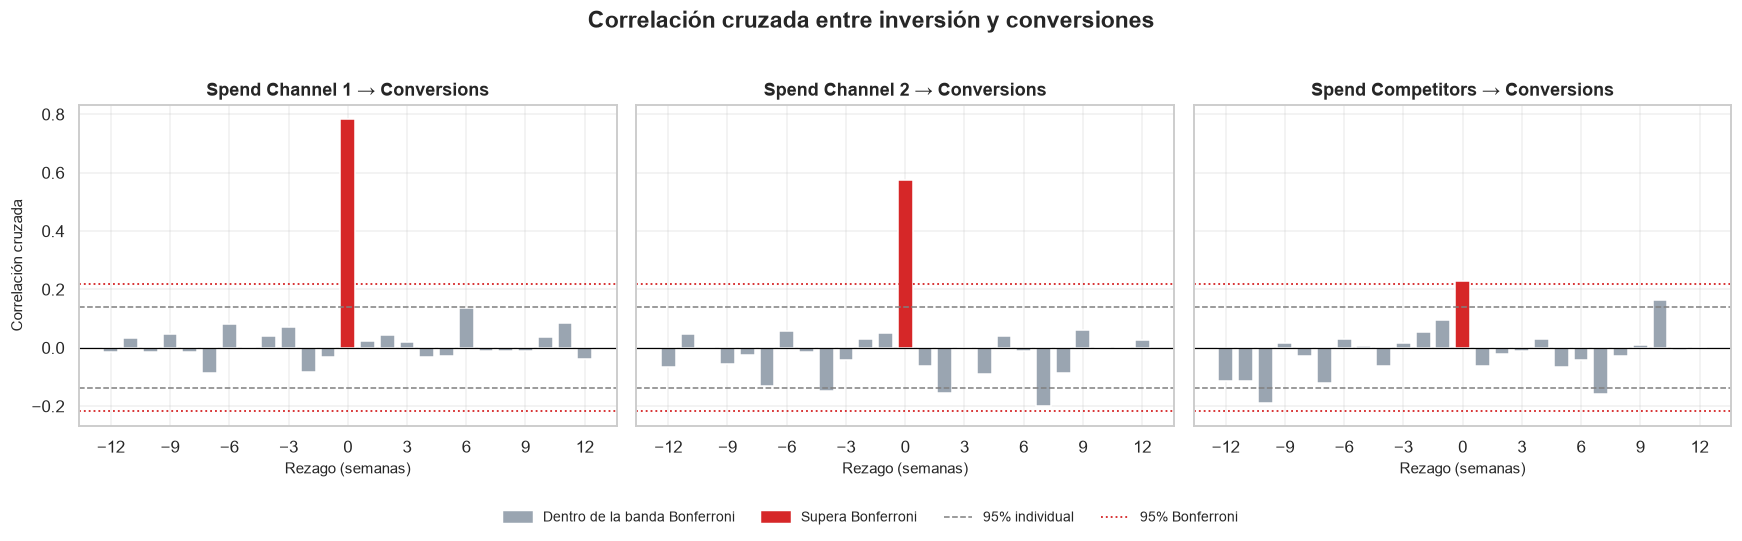

Banda 95% individual: ±0.139 | banda Bonferroni (25 contrastes): ±0.218


In [20]:
def ccf_vals(x, y, max_lag=12):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    n = len(x)
    valores = {}
    for k in range(-max_lag, max_lag + 1):
        if k < 0:
            a, b = x[-k:], y[: n + k]
        elif k == 0:
            a, b = x, y
        else:
            a, b = x[: n - k], y[k:]
        valores[k] = np.corrcoef(a, b)[0, 1]
    return pd.Series(valores)


n = len(Datos)
banda_95 = 1.96 / np.sqrt(n)
z_bonf = stats.norm.ppf(1 - 0.025 / (2 * 12))
banda_bonf = z_bonf / np.sqrt(n)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
for ax, col in zip(axes, GASTOS):
    cc = ccf_vals(Datos[col], Datos[OBJETIVO], max_lag=12)
    colores = ["#d62728" if abs(v) > banda_bonf else COLOR_GRIS for v in cc]
    ax.bar(cc.index, cc.values, color=colores, width=0.75)
    ax.axhline(0, color="black", lw=0.8)
    ax.axhline(banda_95, ls="--", color="grey", lw=1)
    ax.axhline(-banda_95, ls="--", color="grey", lw=1)
    ax.axhline(banda_bonf, ls=":", color="#d62728", lw=1.2)
    ax.axhline(-banda_bonf, ls=":", color="#d62728", lw=1.2)
    ax.set_title(f"{col} → {OBJETIVO}")
    ax.set_xlabel("Rezago (semanas)")
    ax.set_xticks(range(-12, 13, 3))
axes[0].set_ylabel("Correlación cruzada")
fig.suptitle("Correlación cruzada entre inversión y conversiones",
             fontsize=15, fontweight="bold", y=1.02)
handles = [
    Patch(color=COLOR_GRIS, label="Dentro de la banda Bonferroni"),
    Patch(color="#d62728", label="Supera Bonferroni"),
    Line2D([0], [0], color="grey", ls="--", lw=1, label="95% individual"),
    Line2D([0], [0], color="#d62728", ls=":", lw=1.2, label="95% Bonferroni"),
]
fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False,
           bbox_to_anchor=(0.5, -0.02))
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()
print(f"Banda 95% individual: ±{banda_95:.3f} | banda Bonferroni (25 contrastes): ±{banda_bonf:.3f}")

In [21]:
filas = []
for col in GASTOS:
    cc = ccf_vals(Datos[col], Datos[OBJETIVO], max_lag=12)
    positivos = cc.drop(0)
    filas.append({
        "Serie": col,
        "r (lag 0)": cc.loc[0],
        "r (lag 1)": cc.loc[1],
        "r (lag 4)": cc.loc[4],
        "r (lag 8)": cc.loc[8],
        "Máx |r| en lags 1–12": positivos.abs().max(),
        "Rezago del máximo": int(positivos.abs().idxmax()),
        "¿Supera Bonferroni?": "Sí" if positivos.abs().max() > banda_bonf else "No",
    })

ccf_tabla = pd.DataFrame(filas).set_index("Serie")
display(ccf_tabla.round(3))

,r (lag 0),r (lag 1),r (lag 4),r (lag 8),Máx |r| en lags 1–12,Rezago del máximo,¿Supera Bonferroni?
Serie,,,,,,,
Spend Channel 1,0.782,0.024,-0.030,-0.010,0.136,6,No
Spend Channel 2,0.576,-0.064,-0.092,-0.086,0.199,7,No
Spend Competitors,0.228,-0.061,0.031,-0.028,0.190,-10,No


**Hallazgo central.** La asociación es fuerte y **contemporánea**: r = 0.78 con el canal 1, 0.58 con el canal 2 y 0.23 con competidores en la misma semana. En cambio, **ningún rezago** supera la banda corregida por Bonferroni; el máximo es 0.20 (canal 2, rezago 7), por debajo del umbral 0.22 y consistente con lo esperable por azar al examinar 24 rezagos. No hay evidencia de carry-over ni de anticipación.

**Implicancia para el modelo.** La especificación contemporánea `Conversions(t) = f(Spend1(t), Spend2(t), SpendCompetitors(t))` es la adecuada. No se requieren variables de adstock, rezagos distribuidos ni términos AR. Si se añadieran, añadirían parámetros sin respaldo en los datos.

## 10. Anomalías, volatilidad y cambios de nivel

### 10.1 Anomalías sobre el residuo de la descomposición

Se marca una observación como candidata a anomalía si su residuo (una vez removidos tendencia y estacionalidad) se aleja más de 3 desviaciones estándar de su media. Las anomalías no se eliminan: se documentan para revisar si responden a eventos de negocio o a errores de carga. También se listan las mayores desviaciones aunque no superen el umbral, para dimensionar los casos frontera.

In [22]:
anomalias = []
for col in SERIES:
    residuo = descomposicion[col].resid
    z = (residuo - residuo.mean()) / residuo.std()
    mascara = z.abs() > 3
    for fecha in residuo.index[mascara]:
        anomalias.append({
            "Fecha": fecha.date(),
            "Serie": col,
            "Valor": Datos.loc[fecha, col],
            "Residuo": residuo.loc[fecha],
            "z estandarizado": z.loc[fecha],
        })

anomalias = (
    pd.DataFrame(anomalias)
    .sort_values(["Fecha", "Serie"])
    .reset_index(drop=True)
)
display(anomalias.round(2))

mayores_desvios = []
for col in SERIES:
    residuo = descomposicion[col].resid
    z = (residuo - residuo.mean()) / residuo.std()
    for fecha in z.abs().sort_values(ascending=False).head(3).index:
        mayores_desvios.append({
            "Fecha": fecha.date(),
            "Serie": col,
            "Valor": Datos.loc[fecha, col],
            "z estandarizado": z.loc[fecha],
        })

mayores_desvios = (
    pd.DataFrame(mayores_desvios)
    .assign(abs_z=lambda d: d["z estandarizado"].abs())
    .sort_values("abs_z", ascending=False)
    .drop(columns="abs_z")
    .head(8)
    .reset_index(drop=True)
)
display(mayores_desvios.round(2))

,Fecha,Serie,Valor,Residuo,z estandarizado
0,2021-06-27,Spend Competitors,114.0,67.67,3.64


,Fecha,Serie,Valor,z estandarizado
0,2021-06-27,Spend Competitors,114.0,3.64
1,2023-08-20,Conversions,24.7,2.76
2,2022-08-14,Spend Competitors,89.4,2.75
3,2024-12-22,Spend Competitors,66.2,2.69
4,2023-08-20,Spend Channel 2,49.0,2.54
5,2022-03-20,Spend Channel 1,262.7,2.53
6,2024-03-10,Spend Channel 2,1.3,-2.50
7,2024-10-20,Spend Channel 1,18.7,-2.46


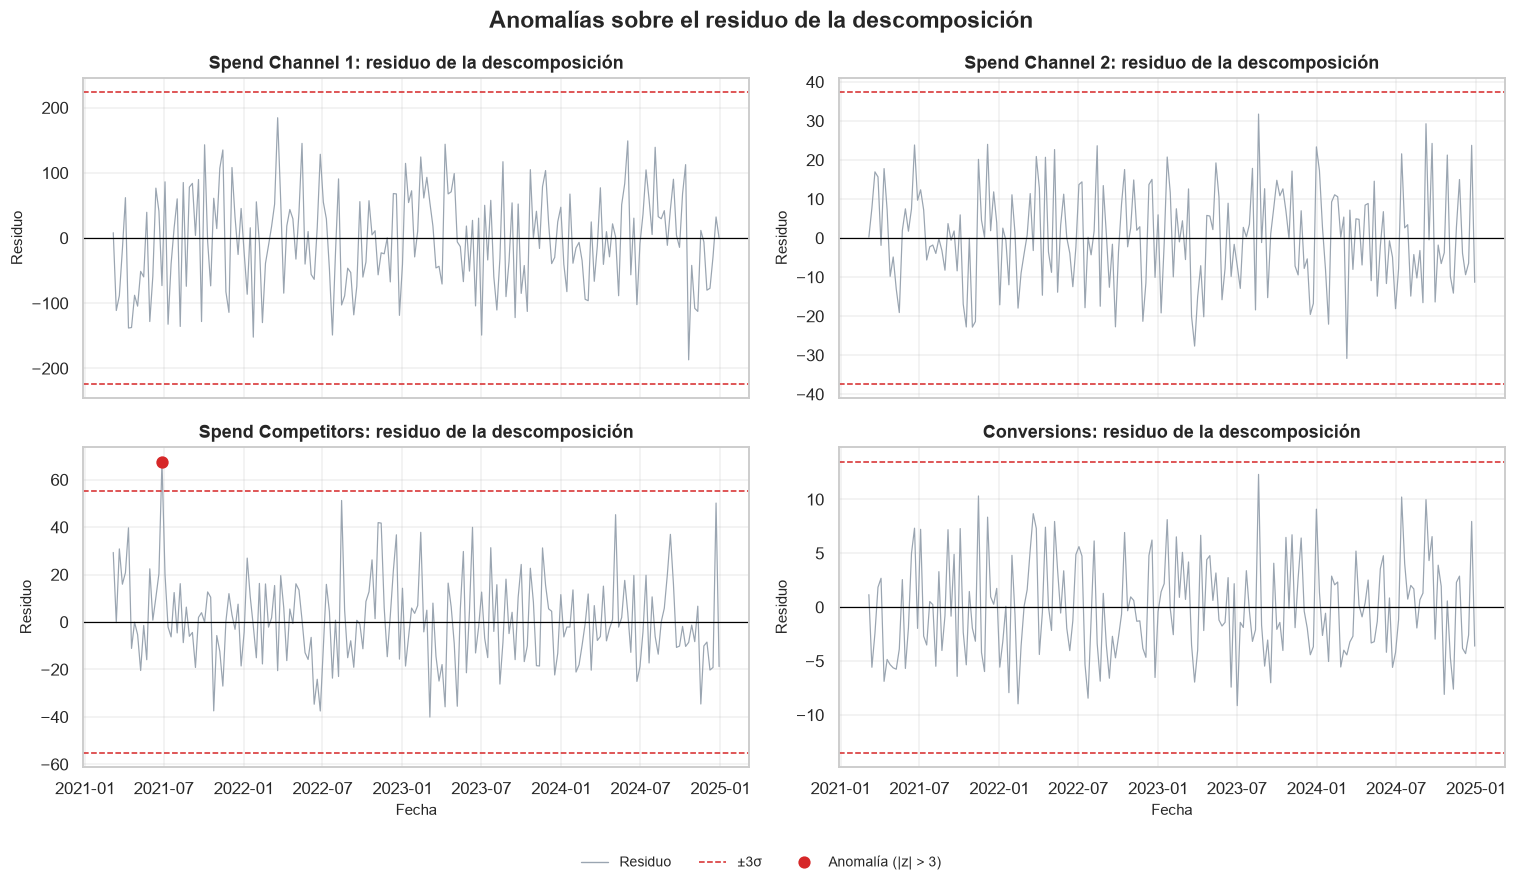

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
for ax, col in zip(axes.ravel(), SERIES):
    residuo = descomposicion[col].resid
    ax.plot(residuo.index, residuo, color=COLOR_GRIS, lw=0.8)
    ax.axhline(0, color="black", lw=0.8)
    ax.axhline(3 * residuo.std(), color="#d62728", ls="--", lw=1)
    ax.axhline(-3 * residuo.std(), color="#d62728", ls="--", lw=1)
    sub = anomalias.loc[anomalias["Serie"] == col, "Fecha"]
    if len(sub) > 0:
        fechas_anom = pd.to_datetime(sub)
        ax.scatter(fechas_anom, residuo.loc[fechas_anom],
                   color="#d62728", s=50, zorder=3)
    ax.set_title(f"{col}: residuo de la descomposición")
    ax.set_ylabel("Residuo")
for ax in axes[1]:
    ax.set_xlabel("Fecha")
handles = [
    Line2D([0], [0], color=COLOR_GRIS, lw=0.9, label="Residuo"),
    Line2D([0], [0], color="#d62728", ls="--", lw=1, label="±3σ"),
    Line2D([0], [0], color="#d62728", marker="o", ls="none", ms=7,
           label="Anomalía (|z| > 3)"),
]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False,
           bbox_to_anchor=(0.5, -0.01))
fig.suptitle("Anomalías sobre el residuo de la descomposición", fontsize=15, fontweight="bold", y=0.98)
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

Con el criterio de 3σ se detecta **una sola semana atípica**: el **27 de junio de 2021**, con una inversión de competidores de **114.0** (z = 3.64), muy por encima de su nivel habitual. Es un pico aislado de presión competitiva, no un cambio de régimen.

El máximo de conversiones (20 de agosto de 2023, 24.7) queda en z = 2.76, por debajo del umbral: es una semana alta, pero no una anomalía estadística. Lo mismo ocurre con el máximo del canal 2 (49.0, z = 2.54). La tabla de mayores desvíos permite revisar estos casos frontera sin reclasificarlos. Ninguna observación se excluye del análisis.

### 10.2 Volatilidad en el tiempo

Se calcula la desviación estándar móvil de 13 semanas y se contrasta la igualdad de varianzas entre años (Levene) y la presencia de heterocedasticidad condicional (ARCH-LM). Una volatilidad cambiante afectaría la validez de los errores estándar del modelo.

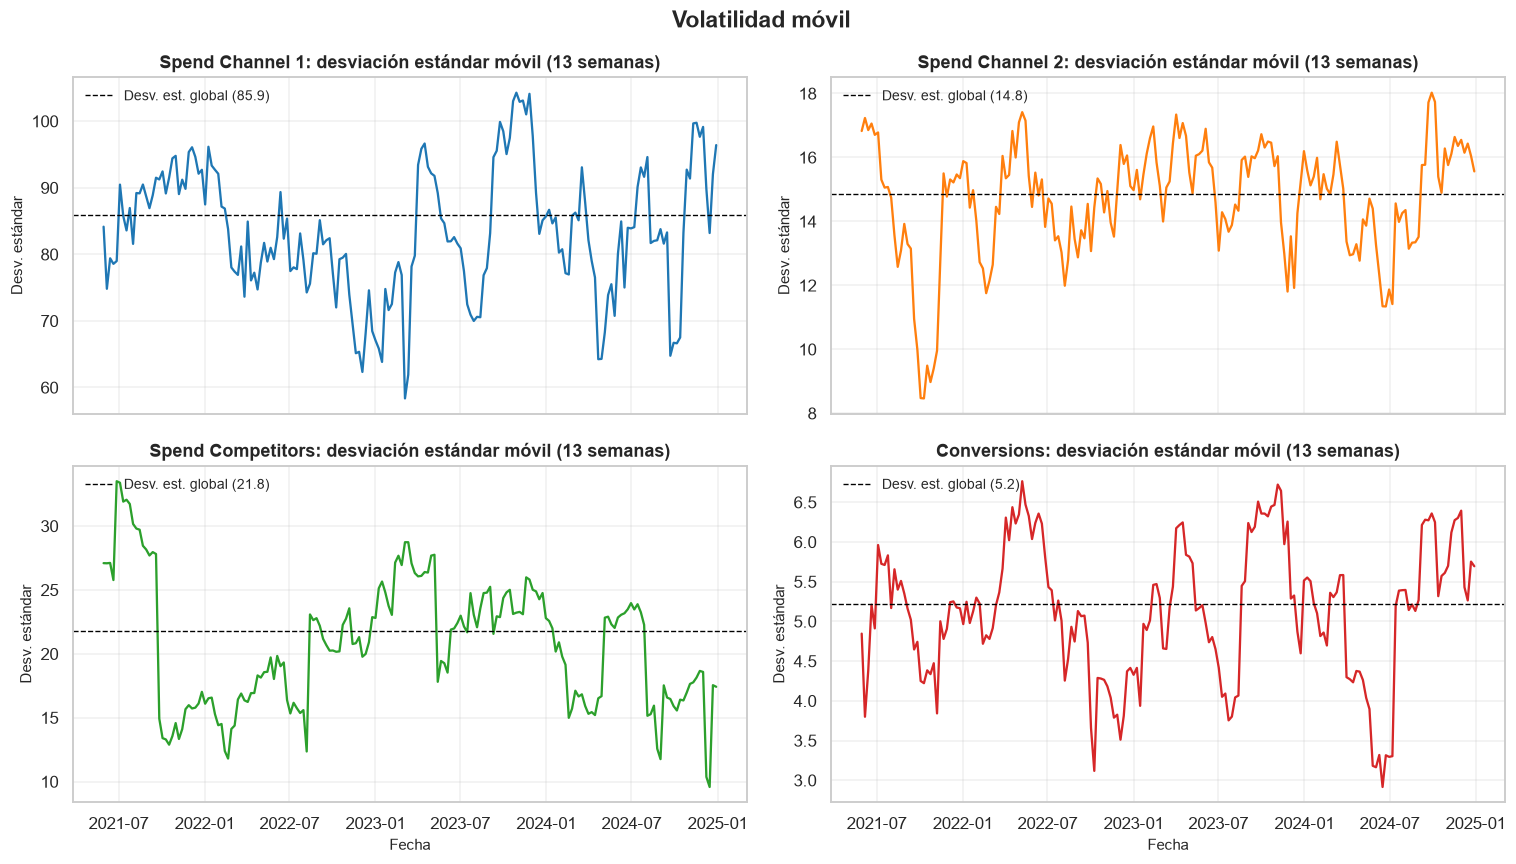

,Levene entre años (p),ARCH-LM(8) (p),¿Volatilidad estable?
Serie,,,
Spend Channel 1,0.3626,0.9250,Sí
Spend Channel 2,0.7661,0.1108,Sí
Spend Competitors,0.1691,0.9556,Sí
Conversions,0.7359,0.4590,Sí


In [24]:
volatilidad = Datos[SERIES].rolling(13, min_periods=13).std()

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
for ax, col in zip(axes.ravel(), SERIES):
    ax.plot(volatilidad.index, volatilidad[col], color=COLORES[col], lw=1.5)
    ax.axhline(Datos[col].std(), color="black", ls="--", lw=0.9,
               label=f"Desv. est. global ({Datos[col].std():.1f})")
    ax.set_title(f"{col}: desviación estándar móvil (13 semanas)")
    ax.set_ylabel("Desv. estándar")
    ax.legend(frameon=False, loc="upper left")
for ax in axes[1]:
    ax.set_xlabel("Fecha")
fig.suptitle("Volatilidad móvil", fontsize=15, fontweight="bold", y=0.98)
plt.tight_layout()
plt.show()

filas = []
for col in SERIES:
    p_levene = stats.levene(*[g[col].dropna().values for _, g in Datos.groupby("Year")]).pvalue
    p_arch = het_arch(Datos[col].values, nlags=8)[1]
    filas.append({
        "Serie": col,
        "Levene entre años (p)": p_levene,
        "ARCH-LM(8) (p)": p_arch,
        "¿Volatilidad estable?": "Sí" if (p_levene > 0.05 and p_arch > 0.05) else "No",
    })

volatilidad_test = pd.DataFrame(filas).set_index("Serie")
display(volatilidad_test.round(4))

La volatilidad móvil oscila, como es esperable en muestras finitas, pero no muestra un cambio estructural: Levene no rechaza igualdad de varianzas entre años (p ≥ 0.17) y ARCH-LM no detecta heterocedasticidad condicional (p ≥ 0.11). La hipótesis de varianza constante es razonable.

### 10.3 Cambios de nivel (CUSUM)

La suma acumulada de desviaciones estandarizadas se mantiene cerca de cero si la media es estable; una deriva sostenida revelaría un cambio de nivel. La banda ±2√k es una referencia aproximada del 95% para ruido independiente.

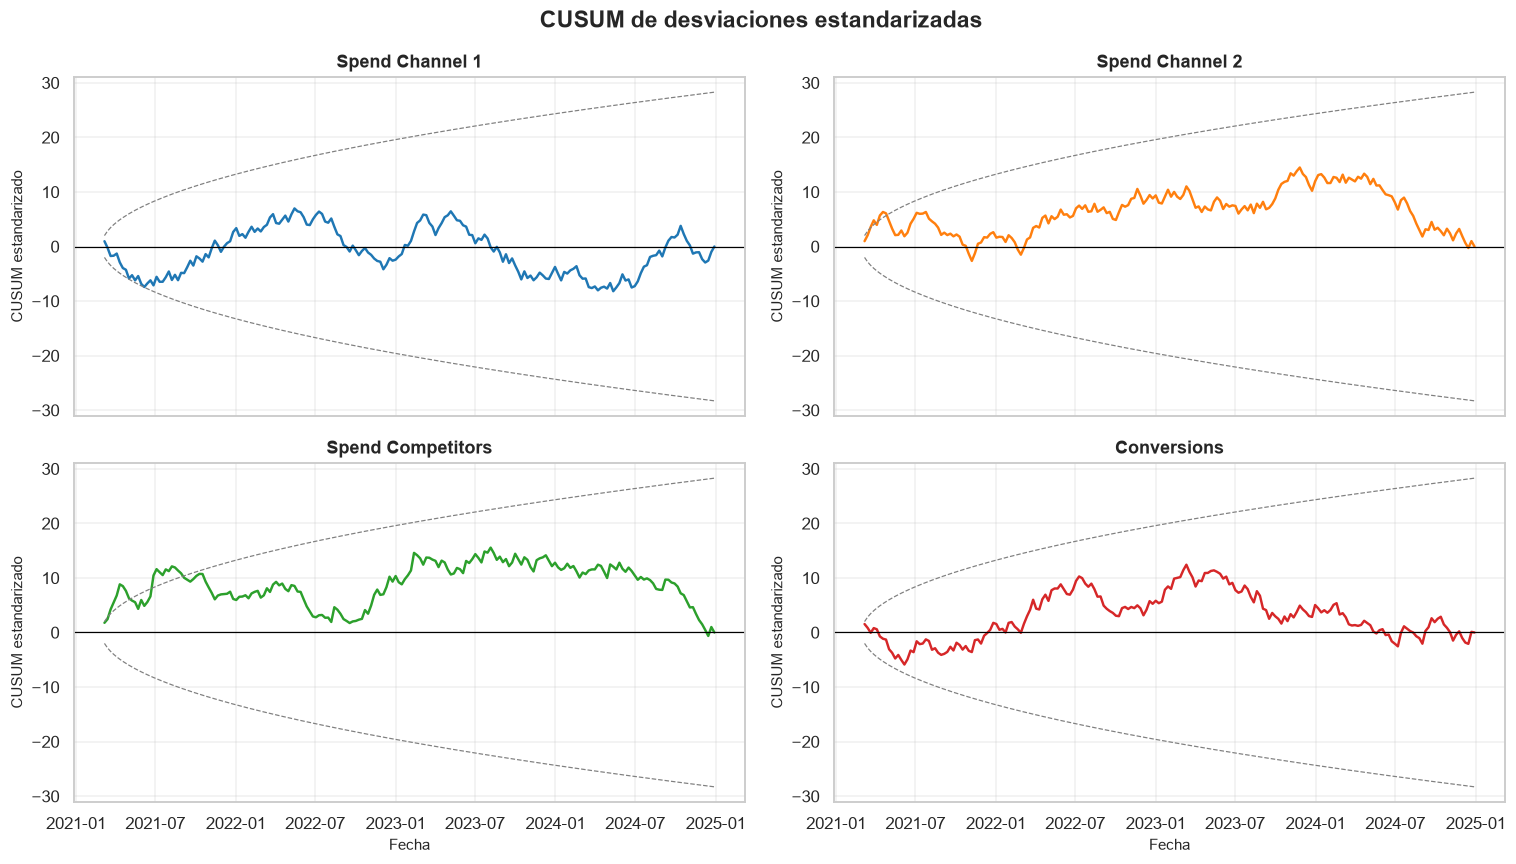

,Semanas fuera de banda,Máx |CUSUM|
Spend Channel 1,0,8.20
Spend Channel 2,5,14.48
Spend Competitors,17,15.55
Conversions,0,12.42


In [25]:
z = (Datos[SERIES] - Datos[SERIES].mean()) / Datos[SERIES].std()
cusum = z.cumsum()
k = np.arange(1, len(Datos) + 1)
banda_cusum = 2 * np.sqrt(k)

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
for ax, col in zip(axes.ravel(), SERIES):
    ax.plot(cusum.index, cusum[col], color=COLORES[col], lw=1.6, label="CUSUM")
    ax.plot(cusum.index, banda_cusum, color="grey", ls="--", lw=0.8)
    ax.plot(cusum.index, -banda_cusum, color="grey", ls="--", lw=0.8)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(col)
    ax.set_ylabel("CUSUM estandarizado")
for ax in axes[1]:
    ax.set_xlabel("Fecha")
fig.suptitle("CUSUM de desviaciones estandarizadas", fontsize=15, fontweight="bold", y=0.98)
plt.tight_layout()
plt.show()

excede = (cusum.abs().to_numpy() > banda_cusum[:, None]).sum(axis=0)
display(pd.DataFrame({
    "Semanas fuera de banda": excede,
    "Máx |CUSUM|": cusum.abs().max().round(2),
}, index=SERIES))

El CUSUM del canal 1 y de las conversiones permanece dentro de la banda durante todo el periodo. En el canal 2 y en competidores se sale de la banda **solo al inicio de la muestra** (marzo–agosto de 2021), cuando la serie acumulada aún es corta y los primeros valores son extremos; al final, el CUSUM regresa a cero. No hay evidencia de un **cambio de nivel permanente**: las desviaciones son transitorias y compatibles con una media constante.

---

## 11. Implicancias para el modelo de regresión

Esta sección conecta el EDA con el ejercicio de modelado: si no hay autocorrelación ni estacionalidad, el modelo puede estimarse por MCO contemporáneo, pero deben verificarse los supuestos sobre los residuos y la multicolinealidad.

### 11.1 Estimación y errores estándar

Se estima `Conversions ~ Spend Channel 1 + Spend Channel 2 + Spend Competitors` y se comparan los errores estándar MCO con los HAC (Newey-West). Si la autocorrelación es despreciable, ambos deben ser muy parecidos; si no, los HAC son la referencia.

In [26]:
X = sm.add_constant(Datos[GASTOS])
y = Datos[OBJETIVO]

ols = sm.OLS(y, X).fit()
hac = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": 4})

coeficientes = pd.DataFrame({
    "Coeficiente": ols.params,
    "EE MCO": ols.bse,
    "p-valor MCO": ols.pvalues,
    "EE HAC": hac.bse,
    "p-valor HAC": hac.pvalues,
})
display(coeficientes.round(4))
print(f"R² = {ols.rsquared:.4f} | R² ajustado = {ols.rsquared_adj:.4f} | n = {int(ols.nobs)}")

,Coeficiente,EE MCO,p-valor MCO,EE HAC,p-valor HAC
const,2.9389,0.3119,0.0000,0.3343,0.0000
Spend Channel 1,0.0458,0.0014,0.0000,0.0019,0.0000
Spend Channel 2,0.1885,0.0086,0.0000,0.0102,0.0000
Spend Competitors,-0.0010,0.0059,0.8599,0.0057,0.8558


R² = 0.8972 | R² ajustado = 0.8956 | n = 200


,Variable,VIF
0,Spend Channel 1,1.005
1,Spend Channel 2,1.145
2,Spend Competitors,1.145


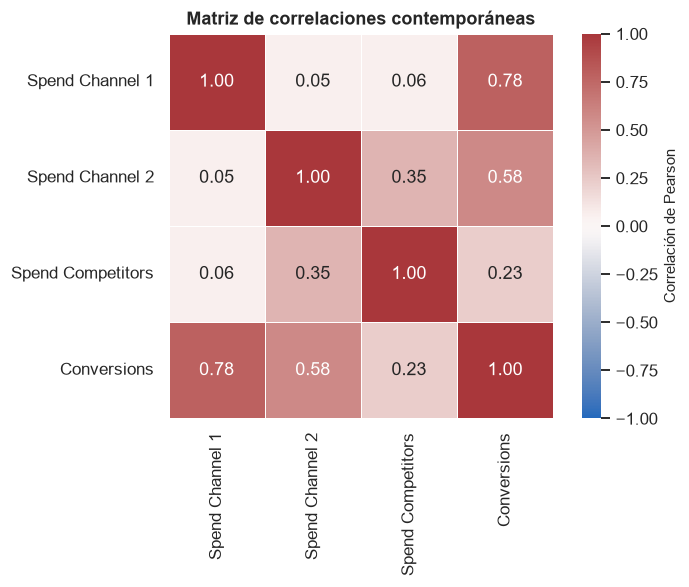

In [27]:
vif = pd.DataFrame({
    "Variable": GASTOS,
    "VIF": [variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])],
})
display(vif.round(3))

matriz_corr = Datos[SERIES].corr(method="pearson")
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(matriz_corr, annot=True, fmt=".2f", cmap="vlag", center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5, ax=ax,
            cbar_kws={"label": "Correlación de Pearson"})
ax.set_title("Matriz de correlaciones contemporáneas")
plt.tight_layout()
plt.show()

### 11.2 Diagnóstico de residuos

Se evalúan los supuestos relevantes para la inferencia:

- **Autocorrelación:** Durbin-Watson (valores cercanos a 2 indican ausencia) y Ljung-Box sobre los residuos.
- **Heterocedasticidad:** Breusch-Pagan.
- **Normalidad:** Jarque-Bera (con n = 200, su incumplimiento afecta poco a la inferencia asintótica, pero conviene reportarlo).
- **Estabilidad:** CUSUM de los residuos del modelo.

In [28]:
dw = durbin_watson(ols.resid)
lb_resid = acorr_ljungbox(ols.resid, lags=[4, 8, 13, 26], return_df=True)
bp = het_breuschpagan(ols.resid, X)
jb = stats.jarque_bera(ols.resid)
cusum_test = breaks_cusumolsresid(ols.resid, ddof=4)

diagnostico = pd.DataFrame({
    "Prueba": [
        "Durbin-Watson",
        "Ljung-Box (4 rezagos), p",
        "Ljung-Box (8 rezagos), p",
        "Ljung-Box (13 rezagos), p",
        "Ljung-Box (26 rezagos), p",
        "Breusch-Pagan, p",
        "Jarque-Bera, p",
        "CUSUM de residuos, p",
    ],
    "Resultado": [
        dw,
        lb_resid.loc[4, "lb_pvalue"],
        lb_resid.loc[8, "lb_pvalue"],
        lb_resid.loc[13, "lb_pvalue"],
        lb_resid.loc[26, "lb_pvalue"],
        bp[1],
        jb.pvalue,
        cusum_test[1],
    ],
})
display(diagnostico.round(4))

,Prueba,Resultado
0,Durbin-Watson,2.0836
1,"Ljung-Box (4 rezagos), p",0.5172
2,"Ljung-Box (8 rezagos), p",0.7894
3,"Ljung-Box (13 rezagos), p",0.9207
4,"Ljung-Box (26 rezagos), p",0.8839
5,"Breusch-Pagan, p",0.1623
6,"Jarque-Bera, p",0.0000
7,"CUSUM de residuos, p",0.4873


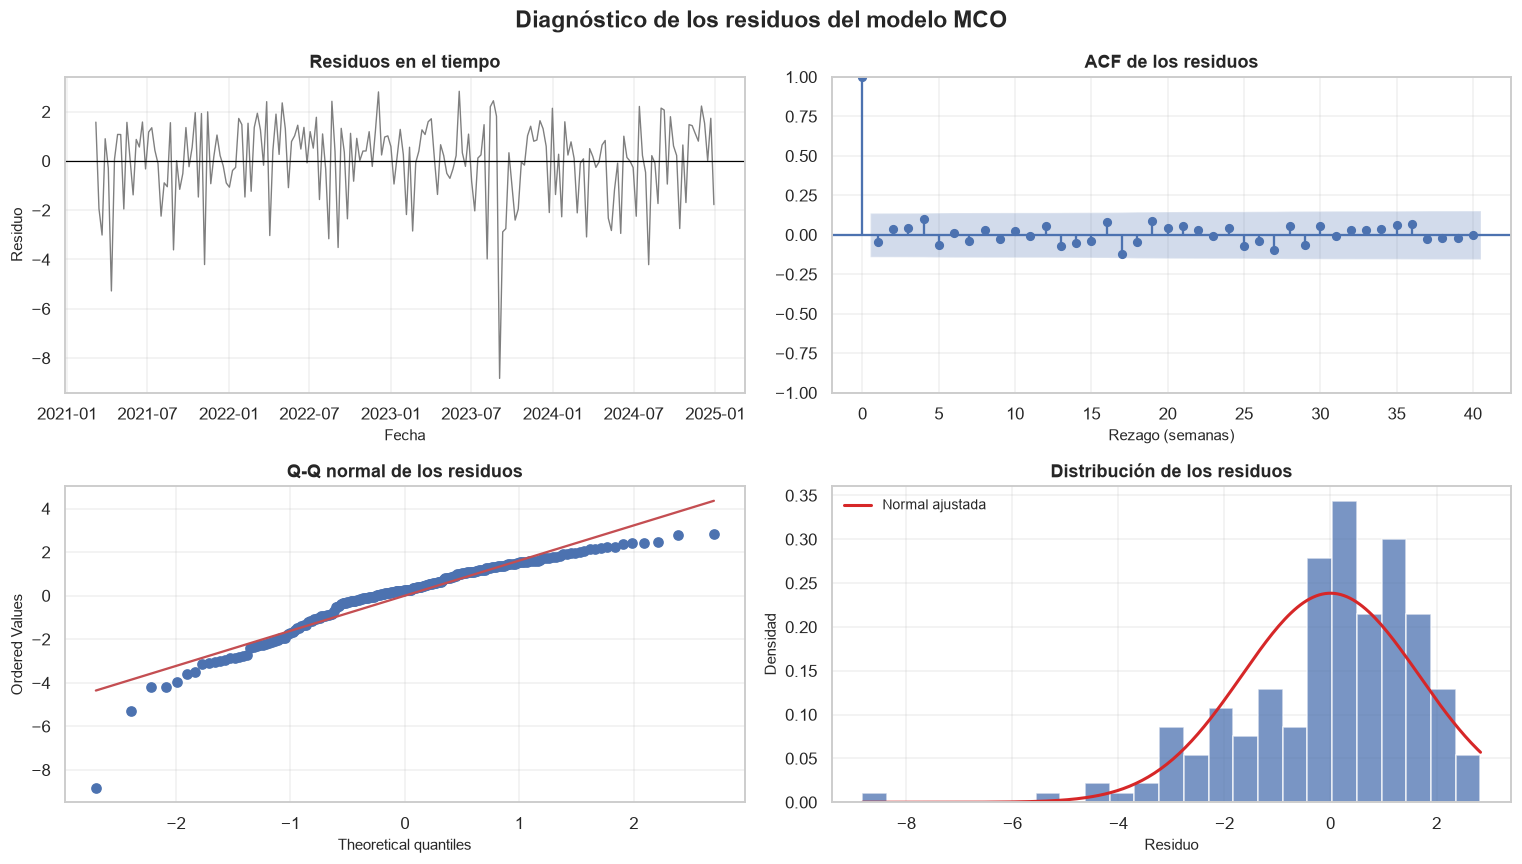

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

axes[0, 0].plot(Datos.index, ols.resid, color="#7f7f7f", lw=0.9)
axes[0, 0].axhline(0, color="black", lw=0.8)
axes[0, 0].set_title("Residuos en el tiempo")
axes[0, 0].set_xlabel("Fecha")
axes[0, 0].set_ylabel("Residuo")

plot_acf(ols.resid, lags=40, alpha=0.05, ax=axes[0, 1], title="ACF de los residuos")
axes[0, 1].set_xlabel("Rezago (semanas)")

stats.probplot(ols.resid, dist="norm", plot=axes[1, 0])
axes[1, 0].set_title("Q-Q normal de los residuos")

axes[1, 1].hist(ols.resid, bins=25, color="#4c72b0", alpha=0.75, density=True,
                edgecolor="white")
x_grid = np.linspace(ols.resid.min(), ols.resid.max(), 200)
axes[1, 1].plot(x_grid, stats.norm.pdf(x_grid, ols.resid.mean(), ols.resid.std()),
                color="#d62728", lw=2, label="Normal ajustada")
axes[1, 1].set_title("Distribución de los residuos")
axes[1, 1].set_xlabel("Residuo")
axes[1, 1].set_ylabel("Densidad")
axes[1, 1].legend(frameon=False)

fig.suptitle("Diagnóstico de los residuos del modelo MCO", fontsize=15, fontweight="bold", y=0.98)
plt.tight_layout()
plt.show()

**Lectura del diagnóstico.**

- **Sin autocorrelación:** Durbin-Watson ≈ 2.08 y Ljung-Box con p ≥ 0.52 en todos los horizontes. Los residuos no conservan memoria, tal como anticipaba el análisis univariado.
- **Sin heterocedasticidad:** Breusch-Pagan p ≈ 0.16; no se rechaza varianza constante.
- **Normalidad:** Jarque-Bera rechaza normalidad (p < 0.001) por colas ligeramente pesadas. Con n = 200 la inferencia MCO es asintóticamente válida; además, los errores HAC son algo mayores en los canales (hasta +36%) pero no cambian ninguna conclusión de significancia, lo que confirma que la inferencia no depende de ese supuesto.
- **Estabilidad:** CUSUM p ≈ 0.49; no hay evidencia de quiebre en los coeficientes.
- **Multicolinealidad:** VIF ≤ 1.15, muy por debajo del umbral habitual de 5. Los regresores aportan información distinta.

En conjunto, el modelo contemporáneo es adecuado y **no requiere correcciones por estructura temporal**.

---

## 12. Conclusiones y próximos pasos

### Hallazgos principales

1. **Cobertura.** 200 semanas consecutivas (2021-03-07 a 2024-12-29), sin duplicados ni valores perdidos. 2021 está incompleto (43 semanas); las 9 semanas que la versión previa mostraba como faltantes son anteriores al estudio, no datos perdidos.
2. **Sin tendencia.** Ninguna serie tiene tendencia lineal significativa al 5% con errores HAC. La caída de la inversión de competidores es marginal (p ≈ 0.06, ≈ −3.0 por año). Las conversiones se mantienen en torno a 14 por semana.
3. **Sin estacionalidad.** Los R² de dummies mensuales son 4–9%, las pruebas F y Kruskal-Wallis no rechazan igualdad entre meses y ACF(52) está dentro de la banda. El componente estacional de la descomposición clásica no es evidencia suficiente con menos de cuatro ciclos.
4. **Estacionariedad y ausencia de memoria.** ADF rechaza raíz unitaria y KPSS no rechaza estacionariedad. Ljung-Box no detecta autocorrelación en 4, 8, 13, 26 ni 52 semanas. No se requiere diferenciación ni componentes AR/MA.
5. **Relación contemporánea, sin carry-over.** La correlación es fuerte en la misma semana (0.78 canal 1, 0.58 canal 2, 0.23 competidores), pero ningún rezago supera la banda corregida por comparaciones múltiples. El modelo debe ser contemporáneo.
6. **Volatilidad estable y una anomalía.** Una sola observación (0.5%) supera 3σ: el pico aislado de competidores del 27-06-2021 (114.0). La varianza es estable entre años (Levene p ≥ 0.17; ARCH-LM p ≥ 0.11) y no hay cambios de nivel permanentes. El CUSUM solo se sale de la banda al inicio de 2021 en canal 2 y competidores, de forma transitoria.
7. **Eficiencia bajo presión.** Entre 2022 y 2024 la inversión propia media subió +5.9%, pero las conversiones semanales cayeron −5.9%; el CPA global subió de 11.4 a 12.8 (+12.6%). La caída de 2024 coincide con recortes en el canal 2 y menor presión de competidores, mientras el canal 1 aumentó. Es una señal para revisar la asignación, no una conclusión causal.

### Implicancias para el modelado

- Estimar por **MCO contemporáneo** con los tres regresores; no añadir rezagos, adstock ni términos ARIMA.
- Reportar **errores HAC** como robustez: en este caso confirman los MCO.
- Mantener la **partición temporal** (`shuffle=False`) para reproducir el uso real del modelo, aunque la ausencia de autocorrelación hace que una partición aleatoria no introduzca fuga de información.
- **No comparar totales anuales de 2021** con años completos; usar promedios semanales o anualizar.
- Reevaluar estacionalidad y carry-over cuando se disponga de **más años o datos semanales por canal/geografía**; con 200 semanas el poder estadístico para ciclos anuales es limitado.

### Próximos pasos

1. Estimar y comparar los modelos de regresión en `13_modelo_regresion.ipynb`.
2. Analizar la respuesta no lineal (saturación) de cada canal, insumo para las curvas de respuesta de la Parte II.
3. Monitorear el CPA por canal y la evolución del canal 2, cuyo recorte de 2024 no se tradujo en una caída proporcional de conversiones.